# Study of the theoretical SNR for the MAGIC telescopes and the LST-1
Containing plots of every parameter used to create the curves

Theoretical SNR of `Instrument.noise_budget`, together with everything about each
observation that the binary files do not record and that could explain the disparity.

**Sources**
- `kbo_occultation/data/observations/observation_log.yaml`: stars, magnitudes (SIMBAD B and V), coordinates, good-time windows, faulty mirrors, eLog notes.
- `kbo_occultation/data/observations/conditions/<night>/`: weather, pyrometer, AMC, starguider and CC pointing, extracted from the MAGIC CC `.rep` files by `kbo-night prepare`.
- `DCs/<night>/dc_report.pkl`: slow DC reports (needs `magic_spysii` to unpickle).
- Zd, airmass and moon are computed with astropy from the coordinates and the run times, and cross-checked against the CC reports.

**Reference:** the instrument model (`kbo_occultation/simulation/instruments.py`, written by Tarek Hassan) is a port of
`CTA_in_optical/Calculate_CTA_telescopes_sensitivity_optical.ipynb`. This notebook redoes that notebook's plots for
La Palma, MAGIC and LST-1 (MST-N with `SHOW_MST = True`) straight from the `Instrument` methods, so every curve is the
package's own number. Where the package looks wrong or incomplete, a **notebook-only corrected value** is shown next to
it (helpers in the second cell). The package is not changed here; the findings are collected in section 14.

In [27]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time

from kbo_occultation import config
from kbo_occultation.observations.log import load_observation_log, nights_table, observations_table, validate
from kbo_occultation.observations.cc_reports import load_conditions, pointing_conditions, conditions_table
from kbo_occultation.observations.dc_combine import load_dc_series, combine_lightcurve_with_dc
from kbo_occultation.simulation.detectability import bin_average
from kbo_occultation.analysis.snr import (N_BINS, DETREND_WINDOW_S, DC_CUT_HZ, load_lightcurves, nsb_table,
                                          measured_snr_table, theoretical_snr_table, plot_snr_vs_magnitude)
from kbo_occultation.analysis.snr_measurement import (good_time_lightcurve, detrended_snr, band_noise_rms,
                                                      noise_vs_bin_size, frame_noise, variance_estimator_floor)

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

log = load_observation_log()
NIGHTS = log.select()   # skips nights/observations with `exclude:` in the log; log.select(include_excluded=True) for all
NIGHT_COLORS = dict(zip(log.nights, ["tab:blue", "tab:red", "tab:green"]))
TELESCOPES = {ch: config.ORM_ARRAY.by_channel(ch) for ch in "ABC"}
MARKERS = {"MAGIC-1": "s", "MAGIC-2": "o", "LST-1": "^"}

In [28]:
import re
import yaml
import astropy.units as u
from astropy.io import fits

from kbo_occultation import PACKAGE_DATA
from kbo_occultation.simulation.instruments import Instrument, FRAME_SAMPLES_DURATION_S, reference_files_path
from kbo_occultation.analysis.snr import snr_report
from kbo_occultation.analysis.snr_measurement import throughput_from_faulty_panels
from kbo_occultation.observations.cc_reports import conditions_table

SITE = "LaPalma"
SHOW_MST = False                     # True adds the CTAO-North MST (NectarCAM) to every plot
TELS = ["MAGIC", "LST"] + (["MST-N"] if SHOW_MST else [])
INSTR = {t: Instrument(t, site=SITE) for t in TELS}
INSTR_SII = {t: Instrument(t, filter_type="MAGIC_SII", site=SITE) for t in TELS}
TEL_COLORS = {"MAGIC": "#2a78d6", "LST": "#eb6834", "MST-N": "#1baf7a"}
STEP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
KIND = {"MAGIC-1": "MAGIC", "MAGIC-2": "MAGIC", "LST-1": "LST"}      # data telescope -> Instrument type
DC_KEY = {t.name: t.dc_key for t in config.ORM_ARRAY.telescopes}

WL = INSTR["MAGIC"].default_wavelengths.astype(float)   # 100-999 nm, 1 nm: the grid the package integrates on
BIN_MS = np.logspace(-3, 3, 61)                           # bin times for the "vs time" plots (1 us - 1 s)
MAG_GRID = np.linspace(5.5, 9.0, 36)                      # our stars are B = 5.95-8.62
REF_MAG, REF_BIN = 7.0, 10 * u.ms                         # reference star and bin for single-number comparisons
BAND = "B"                                                # magnitude band fed to the theory (as kbo-night snr)
trapz = getattr(np, "trapezoid", None) or np.trapz

def tel_axes(ncols=None, **kw):
    fig, axes = plt.subplots(1, len(TELS) if ncols is None else ncols, figsize=(6.5 * len(TELS), 5.8),
                             squeeze=False, **kw)
    return fig, axes[0]

In [29]:
# ---- notebook-only corrected model (NOT in the package) ------------------------------------------------
H_SCALE_M = 8000.0                  # atmospheric scale height in the scintillation formulas
SCINT_CY = 1.5                      # Osborn et al. 2015 empirical coefficient for La Palma (package default too)
WIND_MS = 20.0                      # ASSUMED turbulence-weighted wind speed: sets the short/long-exposure crossover
VEGA_MAG = 0.03                     # CALSPEC Vega: V = 0.03, B - V ~ 0
FOCAL_MM = {"MAGIC": 17000.0, "LST": 28000.0, "MST-N": 16000.0}
R80_OVER_SIGMA = np.sqrt(2 * np.log(5))          # 2D Gaussian: r80 = 1.794 sigma; r39 = sigma
SPT_TEFF = {"B5": 15000, "B8": 12000, "B9": 10500, "B9.5": 10000, "A0": 9600}

# Bessell (1990) Johnson B response, approximate (no B filter file in the package)
_BESSELL_B = np.array([[360, 0.0], [370, .030], [380, .134], [390, .567], [400, .920], [410, .978], [420, 1.0],
                       [430, .978], [440, .935], [450, .853], [460, .740], [470, .640], [480, .536], [490, .424],
                       [500, .325], [510, .235], [520, .150], [530, .095], [540, .043], [550, .009], [560, 0.0]])
BESSELL_B = np.interp(WL, *_BESSELL_B.T, left=0, right=0)


def vega_photon_density(wl_nm):
    """CALSPEC Vega (alpha_lyr_stis_011.fits) photon flux density [ph cm^-2 s^-1 A^-1]."""
    d = fits.getdata(f"{PACKAGE_DATA}/alpha_lyr_stis_011.fits")
    lam_a, flam = d["WAVELENGTH"], d["FLUX"]                      # A, erg s^-1 cm^-2 A^-1
    phot = flam * lam_a * 1e-8 / (6.62607e-27 * 2.99792e10)
    return np.interp(np.asarray(wl_nm) * 10, lam_a, phot, left=0, right=0)


VEGA_PH = vega_photon_density(WL)


def bb_photons(wl_nm, T):
    """Blackbody photon spectral radiance, arbitrary units (B_lambda * lambda / hc)."""
    x = 1.4388e7 / (wl_nm * T)                                    # hc / (lambda k T), lambda in nm
    return wl_nm ** -4 / np.expm1(x)


def teff_from_spectral_type(spt, default=10500):
    m = re.match(r"([OBAFGKM]\d(?:\.\d)?)", spt or "")
    return SPT_TEFF.get(m.group(1), default) if m else default


def response(instr):
    """Total response (atmosphere at instr.airmass x telescope x filter) on WL, as the package integrates it."""
    return instr.total_transmission_filter(WL) if instr.filter_type else instr.total_transmission(WL)


def colour_correction(instr, teff):
    """Photons of a B-normalised blackbody(teff) star relative to a Vega-coloured one (9600 K), in this response."""
    if teff is None:
        return 1.0
    R = response(instr)
    ratio = lambda T: trapz(R * bb_photons(WL, T), WL) / trapz(BESSELL_B * bb_photons(WL, T), WL)
    return ratio(teff) / ratio(9600.0)


def with_airmass(instr, X, fn):
    prev = instr.airmass
    instr.set_airmass(X)
    try:
        return fn()
    finally:
        instr.set_airmass(prev)


def star_photons_calspec(instr, mag, t_ms, airmass=1.0, teff=None):
    """Star photo-electrons in t_ms: area x integral(response x Vega photon density) x 10^(-0.4 (m - m_Vega))."""
    def rate():
        R = response(instr)
        return (instr.mirror_area_per_telescope[instr.telescope_type] * 1e4 * trapz(R * VEGA_PH, WL) * 10
                * colour_correction(instr, teff))
    return np.asarray(t_ms) * 1e-3 * with_airmass(instr, airmass, rate) * 10 ** (-0.4 * (np.asarray(mag) - VEGA_MAG))


def hex_pixel_containment(sigma_mm, flat_mm, n=601):
    """Fraction of a centred circular Gaussian (sigma_mm) inside a hexagon of flat-to-flat size flat_mm."""
    a = flat_mm / 2
    x = np.linspace(-a * 2 / np.sqrt(3), a * 2 / np.sqrt(3), n)
    X, Y = np.meshgrid(x, x)
    inside = np.ones_like(X, bool)
    for ang in np.deg2rad([0, 60, 120]):
        inside &= np.abs(X * np.cos(ang) + Y * np.sin(ang)) <= a
    g = np.exp(-(X ** 2 + Y ** 2) / (2 * sigma_mm ** 2)) / (2 * np.pi * sigma_mm ** 2)
    return float(g[inside].sum() * (x[1] - x[0]) ** 2)


def pixel_flat_mm(t):
    return INSTR[t].pixel_FoV_per_telescope[t] * np.deg2rad(1) * FOCAL_MM[t]


HEX_OVER_CIRCLE = (np.sqrt(3) / 2) / (np.pi / 4)   # hexagon (flat-to-flat d) / circle (diameter d) area = 1.103


def aperture_m(instr):
    return 2 * np.sqrt(instr.mirror_area_per_telescope[instr.telescope_type] / np.pi)


def scint_long(D_m, t_s, X=1.0, alt_m=2200.0, c_y=SCINT_CY):
    """Young's long-exposure scintillation as written by Osborn et al. 2015 (eq. 7), SI units: D in metres."""
    return np.sqrt(1e-5 * c_y ** 2 * D_m ** (-4 / 3) / np.asarray(t_s) * X ** 3 * np.exp(-2 * alt_m / H_SCALE_M))


def scint_short(D_m, X=1.0, alt_m=2200.0, c_y=SCINT_CY, v=WIND_MS):
    """
    Short-exposure (t << D/v) scintillation, independent of t (Kenyon et al. 2006, as in Osborn et al. 2015):
    long  sigma^2 = 10.66 D^-4/3 t^-1 X^3 W / v,  short sigma^2 = 17.34 D^-7/3 X^3 W,  W = int h^2 Cn^2 dh.
    W is fixed so that the long-exposure form equals scint_long at wind speed v.
    """
    W = 1e-5 * c_y ** 2 * np.exp(-2 * alt_m / H_SCALE_M) / 10.66 * v
    return np.sqrt(17.34 * D_m ** (-7 / 3) * X ** 3 * W)


def scint_corrected(D_m, t_s, X=1.0, alt_m=2200.0, c_y=SCINT_CY, v=WIND_MS):
    """Smooth join of the two regimes: 1/sigma^2 = 1/sigma_short^2 + 1/sigma_long^2."""
    l2, s2 = scint_long(D_m, t_s, X, alt_m, c_y) ** 2, scint_short(D_m, X, alt_m, c_y, v) ** 2
    return np.sqrt(l2 * s2 / (l2 + s2))


def corrected_budget(instr, mag, tb, airmass=1.0, throughput=1.0, psf=1.0, teff=None,
                     nsb_over_star=None, hex_pixel=True, k=None, elec=True):
    """
    Notebook-only noise budget: package structure, with
      S from CALSPEC Vega (x colour correction, x PSF containment, x mirror throughput, extinction at airmass);
      B from the package NSB x hexagonal pixel area (or nsb_over_star x S, the measured ratio);
      scintillation in metres, joined to the short-exposure regime;
      variance floor scaled by ((S + B) / S)^2.
    """
    t_ms, t_s = tb.to_value(u.ms), tb.to_value(u.s)
    t = instr.telescope_type
    S = star_photons_calspec(instr, mag, t_ms, airmass, teff) * throughput * psf
    if nsb_over_star is not None:
        B = nsb_over_star * S
    else:
        B = instr.number_nsb_photons() * tb.to_value(u.ns) * throughput * (HEX_OVER_CIRCLE if hex_pixel else 1.0)
    F = instr.excess_noise_factor_per_telescope[t]
    var = {"shot": F ** 2 * (S + B) / S ** 2,
           "elec": (instr.elec_noise_per_telescope[t] ** 2 / S ** 2) if elec else 0 * S,
           "scint": scint_corrected(aperture_m(instr), t_s, airmass, instr.site_altitude_m) ** 2 + 0 * S}
    k = instr.variance_estimator_k_per_telescope[t] if k is None else k
    n_frames = np.maximum(1.0, t_s / FRAME_SAMPLES_DURATION_S)
    var["floor"] = 2 * k / instr.variance_estimator_n_samples / n_frames * ((S + B) / S) ** 2
    out = {"star_photons": S, "nsb_photons": B, **{f"sigma_{key}": np.sqrt(v) for key, v in var.items()}}
    out["sigma_total"] = np.sqrt(sum(var.values()))
    return out


def package_budget(instr, mag, tb, **kw):
    """The package's own noise_budget (what kbo-night snr uses)."""
    return instr.noise_budget(mag, tb, **kw)

## 1 - Basic telescope information
Every scalar and data file `Instrument` uses, read back from the instances (MAGIC's mirror and QE scale factors are
derived by dividing by the raw data file), next to the values of `MAGIC-LST.yml` (the intensity-interferometry
configuration shipped in `data/iact_reference_values/`) and of the old notebook.

In [30]:
with open(f"{reference_files_path}/MAGIC-LST.yml") as f:
    II = yaml.safe_load(f)["observatory"]["constants"]
II_IDX = {"MAGIC": 0, "LST": 2}          # MAGIC-LST.yml order: M2, M1, LST1

def raw_file(name, w):
    d = np.loadtxt(f"{reference_files_path}/{name}", delimiter=",", skiprows=1)
    return np.interp(w, d[::np.sign(d[-1, 0] - d[0, 0]).astype(int), 0], d[::np.sign(d[-1, 0] - d[0, 0]).astype(int), 1])

W400 = np.array([400.0])
rows = {}
for t, i in INSTR.items():
    rows[f"{t} (package)"] = {
        "mirror area [m2]": i.mirror_area_per_telescope[t],
        "equivalent aperture D [m]": aperture_m(i),
        "pixel FoV [deg]": i.pixel_FoV_per_telescope[t],
        "pixel size at focal plane [mm]": pixel_flat_mm(t),
        "mirror file": i.mirror_reflectivity_per_telescope[t],
        "mirror scale factor": i.mirror_reflectivity(W400)[0] / raw_file(i.mirror_reflectivity_per_telescope[t], 400.0),
        "QE file": i.qes_per_telescope[t],
        "QE scale factor": i.quantum_efficiency(W400)[0] / raw_file(i.qes_per_telescope[t], 400.0),
        "camera window file": i.camera_transmission_per_telescope[t],
        "telescope transmission (shadowing)": i.transmission_per_telescope[t],
        "funnel (light guide) efficiency": i.funnel_transmission_per_telescope[t],
        "reflectivity @400 nm": i.mirror_reflectivity(W400)[0],
        "QE @400 nm": i.quantum_efficiency(W400)[0],
        "camera window @400 nm": i.camera_transmission(W400)[0],
        "total telescope efficiency @400 nm": i.total_telescope_transmission(W400)[0],
        "PSF containment in pixel": 1.0,
        "excess-noise factor F (variance x F^2)": i.excess_noise_factor_per_telescope[t],
        "electronic noise [p.e. per bin]": i.elec_noise_per_telescope[t],
        "variance-floor k": i.variance_estimator_k_per_telescope[t],
        "NSB, computed [ph/ns/pixel]": i.number_nsb_photons(),
        "NSB, hard-coded dict (unused) [ph/ns/pixel]": i.nsb_per_telescope[t],
        "site altitude [m]": i.site_altitude_m,
    }
for t, j in II_IDX.items():
    g_nofilter = II["g"][j] / 0.93                      # g includes a 93 % optical filter (II campaign)
    rows[f"{t} (MAGIC-LST.yml)"] = {
        "mirror area [m2]": II["area"][j],
        "QE @400 nm": II["alpha_QE"][j],
        "PSF containment in pixel": 0.7 * 0.7 if t == "MAGIC" else 1.0,
        "total telescope efficiency @400 nm": g_nofilter * II["alpha_QE"][j],
        "excess-noise factor F (variance x F^2)": II["F"][j],
        "electronic noise [p.e. per bin]": II["elec_noise"][j],
    }
rows["old notebook"] = {
    "mirror area [m2]": "same (MAGIC 240, LST 380.271)",
    "NSB, hard-coded dict (unused) [ph/ns/pixel]": "same dict; computed LST 0.2579, MST-N 0.2366",
    "camera window file": "same",
    "total telescope efficiency @400 nm": "same chain, star integral 100-800 nm (package 100-1000 nm)",
    "excess-noise factor F (variance x F^2)": "not modelled (pure shot noise)",
}
params = pd.DataFrame(rows)
params

,MAGIC (package),LST (package),MAGIC (MAGIC-LST.yml),LST (MAGIC-LST.yml),old notebook
mirror area [m2],240,380.271,236.000,370.000,"same (MAGIC 240, LST 380.271)"
equivalent aperture D [m],17.481,22.004,NaN,NaN,NaN
pixel FoV [deg],0.1,0.102,NaN,NaN,NaN
pixel size at focal plane [mm],29.671,49.847,NaN,NaN,NaN
mirror file,LST_ref_200_1100_190211a.dat,LST_ref_200_1100_190211a.dat,NaN,NaN,NaN
mirror scale factor,0.82,1.0,NaN,NaN,NaN
QE file,LST_qe_R11920-100-02.dat,LST_qe_R11920-100-02.dat,NaN,NaN,NaN
QE scale factor,0.86,1.0,NaN,NaN,NaN
camera window file,MST-N_No7-10_ave.dat,LST_transmission_lst_window_No7-10_ave.dat,NaN,NaN,same
telescope transmission (shadowing),0.893,0.961,NaN,NaN,NaN


**Reading the table.**
- MAGIC is LST optics with scalars: reflectivity × 0.82, QE × 0.86, the MST shadowing value 0.8928, a 0.85 funnel and the
  MST-N camera window. `optical_filter_MAGIC_QE.txt` is exactly LST QE × 0.86, so the QE is consistent; the other
  scalars are placeholders.
- `MAGIC-LST.yml` efficiency = g / 0.93 (its optical filter removed) × α_QE. For LST-1 it matches the package within
  ~10 %. For MAGIC it is ~2× lower, and the gap is almost exactly its "halo 70 % × PSF-in-pixel 70 %", which the
  package does not have (sections 8 and 13).
- The pixel solid angle is a circle of diameter = FoV in the package; the pixels are hexagons (area × 1.103).
- The hard-coded NSB dictionary is never used (the rate is recomputed from the NSB spectrum) and disagrees with it
  for LST and MST-N.

## 2 - Observation conditions

In [31]:
nights_table(log)

,telescopes,optical_filter,n_stars,dark_run,cc_reports,faulty_panels,elog_notes,exclude
night,,,,,,,,
2025-12-16,MAGIC-2,none,5,dark,m2,"{""m2"": 1}",{'m2': 10.07},None
2026-03-08,"MAGIC-2, LST-1, MAGIC-1",none,3,None,"m1, m2","{""m1"": 35, ""m2"": 19, ""lst1"": null}","{'m1': 9.45, 'm2': 9.02}",None
2026-08-19,"MAGIC-2, LST-1, MAGIC-1",none,4,DarkPatch54,"m1, m2","{""m1"": 11, ""m2"": 2, ""lst1"": null}","{'m1': 11.15, 'm2': 9.71, 'lst1': 46.69}",None


In [32]:
observations_table(log)

type   spectral_type  mag_B  mag_V   ra_deg  dec_deg                start_utc                 stop_utc good_time_s                                              notes exclude
night      observation                                                                                                                                                                               
2025-12-16 HD-4335      star  B9.5IIIp(HgMn)  5.954  6.024   11.545   44.861  2025-12-16T21:23:00.272  2025-12-16T21:31:11.437  [230, 280]                                               None    None
           HD-8837      star            B9IV  6.553  6.587   21.945   40.336  2025-12-16T22:08:19.836  2025-12-16T22:16:06.995    [18, 48]                                               None    None
           HD-22353     star              B9  7.038  7.008   54.347   40.090  2025-12-16T22:23:28.140  2025-12-16T22:29:12.257  [200, 230]                                               None    None
           HD-17316     star              B9  7.530  7.420   42.059   43.623  2025-12-16T22:33:24.927  2025-12-16T22:40:31.075  [300, 380]                                               None    None
           HD-20920     star              B8  7.960  8.030   50.981   41.337  2025-12-16T23:05:22.560  2025-12-16T23:11:59.695  [100, 250]                                               None    None
           dark         dark            None    NaN    NaN      NaN      NaN  2025-12-16T23:15:18.364  2025-12-16T23:22:06.497        None  Dark run used as the NSB reference for the night.    None
2026-03-08 HD-40626     star          B9.5IV  5.998  6.040   90.703   49.906  2026-03-08T22:10:15.176  2026-03-08T22:14:16.258  [120, 163]                                               None    None
           HD-45563     star            B9IV  6.403  6.450   97.070    1.913  2026-03-08T22:25:51.236  2026-03-08T22:29:48.316  [153, 205]                                               None    None
           HD-46016     star              B8  6.970  7.000   98.290   46.476  2026-03-08T22:34:12.372  2026-03-08T22:38:49.466  [101, 166]                                               None    None
2026-08-19 DarkPatch54  dark            None    NaN    NaN  276.980   28.880  2026-08-20T00:51:52.940  2026-08-20T00:57:03.035        None             Dark patch taken just before HD170263.    None
           HD170263     star              B8  8.620  8.620  276.823   28.929  2026-08-20T00:59:06.100  2026-08-20T01:05:01.221    [3, 350]                                               None    None
           HD176914     star              B5  6.927  7.034  285.325   28.412  2026-08-20T01:11:08.220  2026-08-20T01:16:05.320   [68, 115]                                               None    None
           DarkPatch53  dark            None    NaN    NaN  285.150   28.270  2026-08-20T01:18:02.960  2026-08-20T01:23:03.061        None                                               None    None
           HD196243     star              B5  7.480  7.590  308.781   30.253  2026-08-20T01:27:12.868  2026-08-20T01:32:07.963  [215, 290]                                               None    None
           HD199102     star             B9V  8.000  8.020  313.486   29.500  2026-08-20T01:35:09.780  2026-08-20T01:40:05.880   [52, 185]                                               None    None

The theory below uses the **B** magnitude of each star (as `kbo-night snr`). All stars are B5–B9.5, i.e. close to
Vega's colour, which is what the package's Vega scaling assumes.

## 3 - Atmospheric transmission (La Palma)
`Instrument.atmospheric_transmission` reads the MODTRAN optical depth τ(λ) of `atm_trans_2147_1_3_0_0_0.dat`, column
"100 km" (the whole atmosphere above the 2147 m site), and returns exp(−τ·X). The old notebook's plot title said
"h > 12 km", which is wrong: the 12 km curve is the deprecated `LaPalma_atmospheric_transmission.csv`.

package extinction: k(440 nm) = 0.299, k(550 nm) = 0.176 mag/airmass


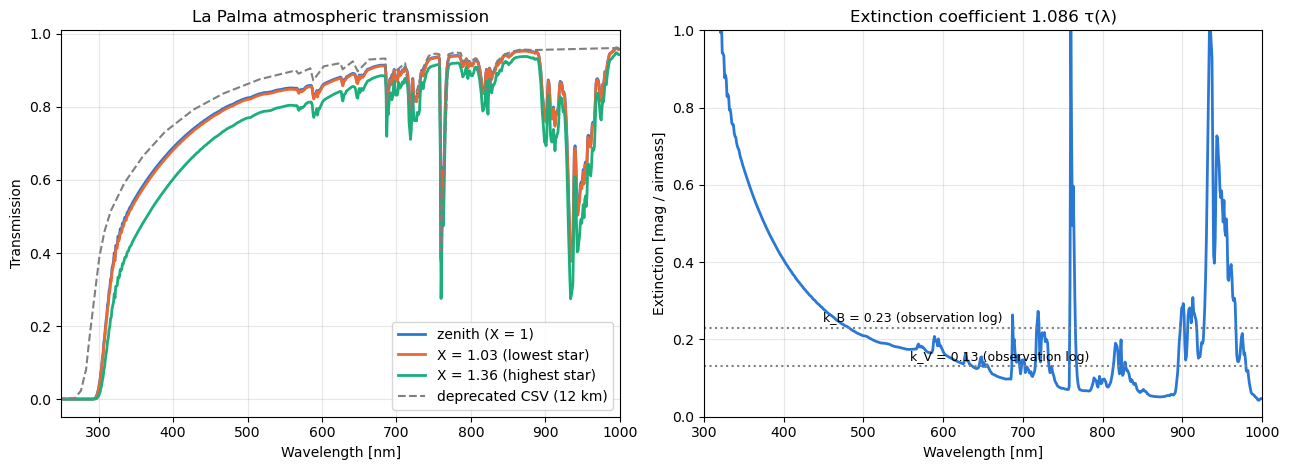

In [33]:
conditions = conditions_table(log)
star_X = conditions.loc[conditions["type"] == "star", "airmass_mean"].dropna()
deprecated = np.loadtxt(f"{reference_files_path}/LaPalma_atmospheric_transmission.csv", delimiter=",", skiprows=1)

i = INSTR["MAGIC"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for X, c, lab in [(1.0, STEP_COLORS[0], "zenith (X = 1)"), (star_X.min(), STEP_COLORS[1], f"X = {star_X.min():.2f} (lowest star)"),
                  (star_X.max(), STEP_COLORS[2], f"X = {star_X.max():.2f} (highest star)")]:
    ax1.plot(WL, with_airmass(i, X, lambda: i.atmospheric_transmission(WL)), color=c, lw=2, label=lab)
ax1.plot(deprecated[:, 0], deprecated[:, 1] / 100, color="grey", ls="--", lw=1.5, label="deprecated CSV (12 km)")
ax1.set(xlabel="Wavelength [nm]", ylabel="Transmission", title="La Palma atmospheric transmission", xlim=(250, 1000))
ax1.legend(); ax1.grid(alpha=0.3)

tau = -np.log(np.clip(i.atmospheric_transmission(WL), 1e-300, None))
k_mag = 2.5 * np.log10(np.e) * tau
ax2.plot(WL, k_mag, color=STEP_COLORS[0], lw=2, label="package (MODTRAN)")
for band, lam in [("B", 440), ("V", 550)]:
    ax2.axhline(log.site["extinction_k"][band], color="grey", ls=":", lw=1.5)
    ax2.annotate(f"k_{band} = {log.site['extinction_k'][band]} (observation log)", (lam, log.site["extinction_k"][band]),
                 textcoords="offset points", xytext=(5, 4), fontsize=9)
ax2.set(xlabel="Wavelength [nm]", ylabel="Extinction [mag / airmass]", xlim=(300, 1000), ylim=(0, 1.0),
        title="Extinction coefficient 1.086 τ(λ)")
ax2.grid(alpha=0.3)
plt.tight_layout()
print("package extinction: k(440 nm) = %.3f, k(550 nm) = %.3f mag/airmass" % (k_mag[WL == 440][0], k_mag[WL == 550][0]))
plt.savefig(f"./Atmospheric_transmission_and_Extinction.png", dpi=200)
plt.show()


## 4 - The optical chain, factor by factor
Mirror reflectivity, photodetector QE and camera window (old notebook cells 13, 16, 19). For MAGIC the dotted line is
`optical_filter_MAGIC_QE.txt`, the MAGIC QE curve shipped with the filters.

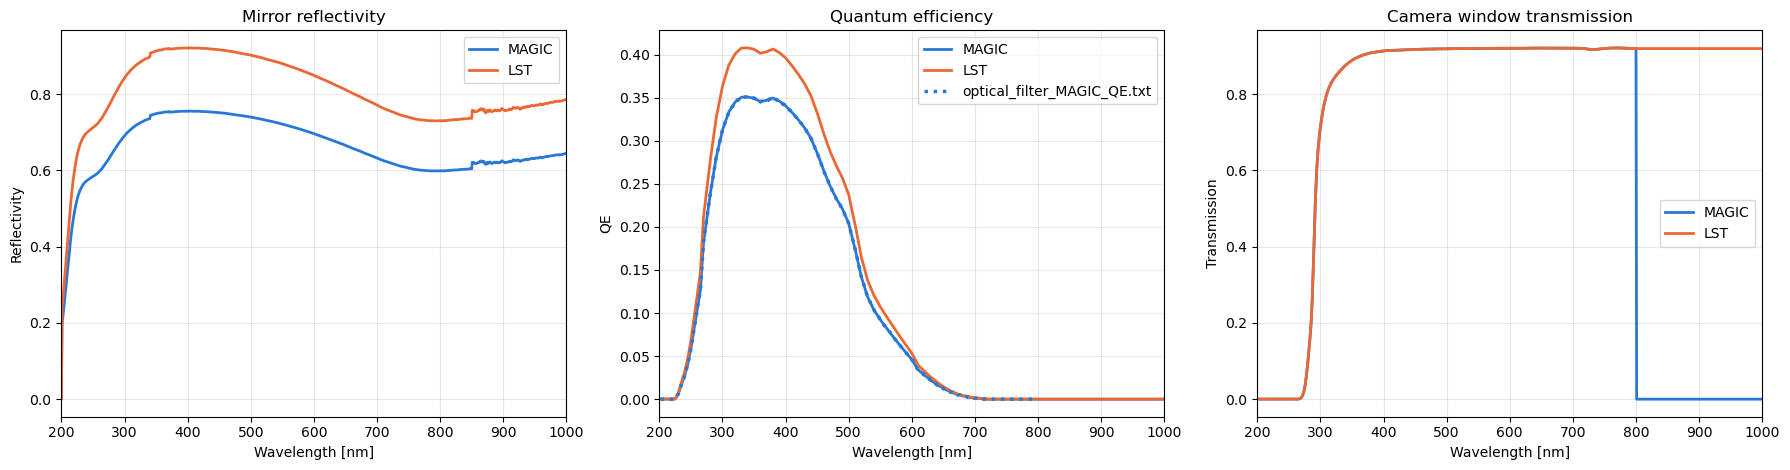

In [34]:
magic_qe = np.loadtxt(f"{PACKAGE_DATA}/optical_filters/optical_filter_MAGIC_QE.txt")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for t, i in INSTR.items():
    c = TEL_COLORS[t]
    axes[0].plot(WL, i.mirror_reflectivity(WL), color=c, lw=2, label=t)
    axes[1].plot(WL, i.quantum_efficiency(WL), color=c, lw=2, label=t)
    axes[2].plot(WL, i.camera_transmission(WL), color=c, lw=2, label=t)
axes[1].plot(magic_qe[:, 0], magic_qe[:, 1] / 100, color=TEL_COLORS["MAGIC"], ls=":", lw=2.5,
             label="optical_filter_MAGIC_QE.txt")
for ax, title, yl in zip(axes, ["Mirror reflectivity", "Quantum efficiency", "Camera window transmission"],
                         ["Reflectivity", "QE", "Transmission"]):
    ax.set(xlabel="Wavelength [nm]", ylabel=yl, title=title, xlim=(200, 1000))
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout() 
plt.savefig(f"./MirrorRefl_QE_and_CameraTrans.png", dpi=200)
plt.show()

The total response is built one factor at a time (old notebook cell 22, now at La Palma and zenith). The star sees
every factor; the NSB (section 7) sees all but the atmosphere.

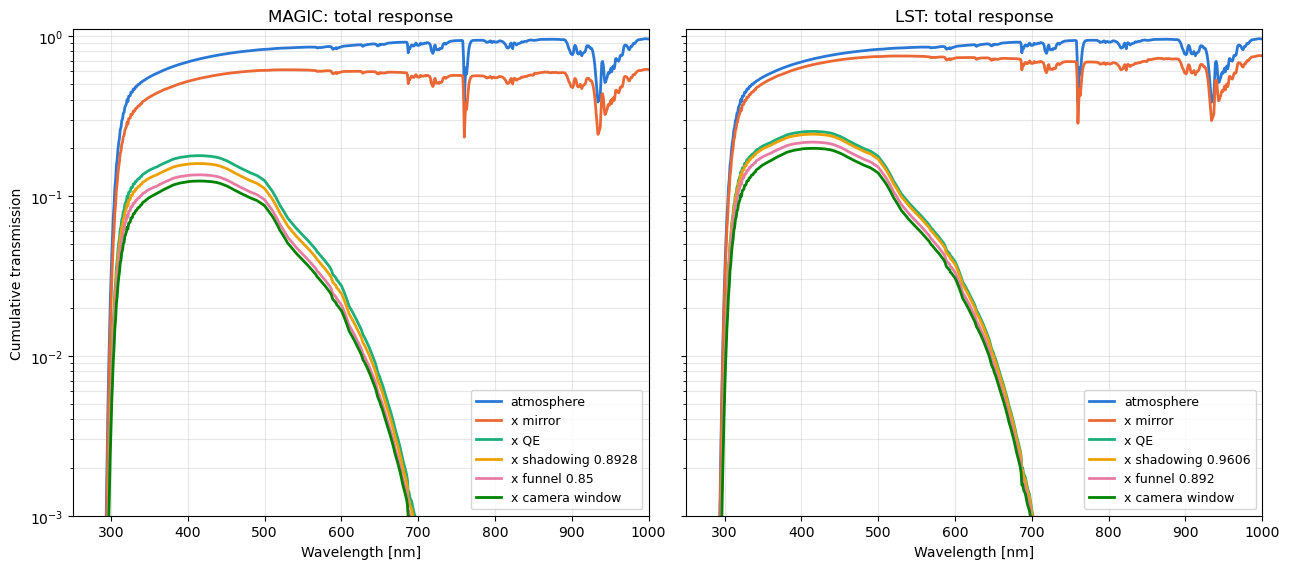

,MAGIC,LST
peak response,0.124,0.198
wavelength of peak [nm],416.000,416.000
integral of response [nm],24.894,39.858
response-weighted wavelength [nm],443.626,443.626


In [35]:
fig, axes = tel_axes(sharey=True)
for ax, (t, i) in zip(axes, INSTR.items()):
    steps = [("atmosphere", i.atmospheric_transmission(WL)),
             ("x mirror", i.mirror_reflectivity(WL)),
             ("x QE", i.quantum_efficiency(WL)),
             (f"x shadowing {i.transmission_per_telescope[t]}", i.transmission_per_telescope[t] + 0 * WL),
             (f"x funnel {i.funnel_transmission_per_telescope[t]}", i.funnel_transmission_per_telescope[t] + 0 * WL),
             ("x camera window", i.camera_transmission(WL))]
    cum = np.ones_like(WL)
    for (lab, f), c in zip(steps, STEP_COLORS):
        cum = cum * f
        ax.plot(WL, cum, color=c, lw=2, label=lab)
    assert np.allclose(cum, i.total_transmission(WL))
    ax.set(yscale="log", ylim=(1e-3, 1.1), xlim=(250, 1000), xlabel="Wavelength [nm]", title=f"{t}: total response")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
axes[0].set_ylabel("Cumulative transmission")
plt.tight_layout()
plt.savefig(f"./MAGIC_LST1_Total_response.png", dpi=200)
plt.show()

eff = pd.DataFrame({t: {"peak response": response(i).max(),
                        "wavelength of peak [nm]": WL[np.argmax(response(i))],
                        "integral of response [nm]": trapz(response(i), WL),
                        "response-weighted wavelength [nm]": trapz(WL * response(i) * VEGA_PH, WL) / trapz(response(i) * VEGA_PH, WL)}
                    for t, i in INSTR.items()})
eff

## 5 - Optical filters
The 2026 campaign used no filter. For reference: the MAGIC SII filter and the SDSS ugriz set (old notebook cell 25),
then the full response with and without SII. Shaded: `Instrument.response_band()` (where the response is above 1 % of
its peak), which is the band the diffraction simulation integrates over.

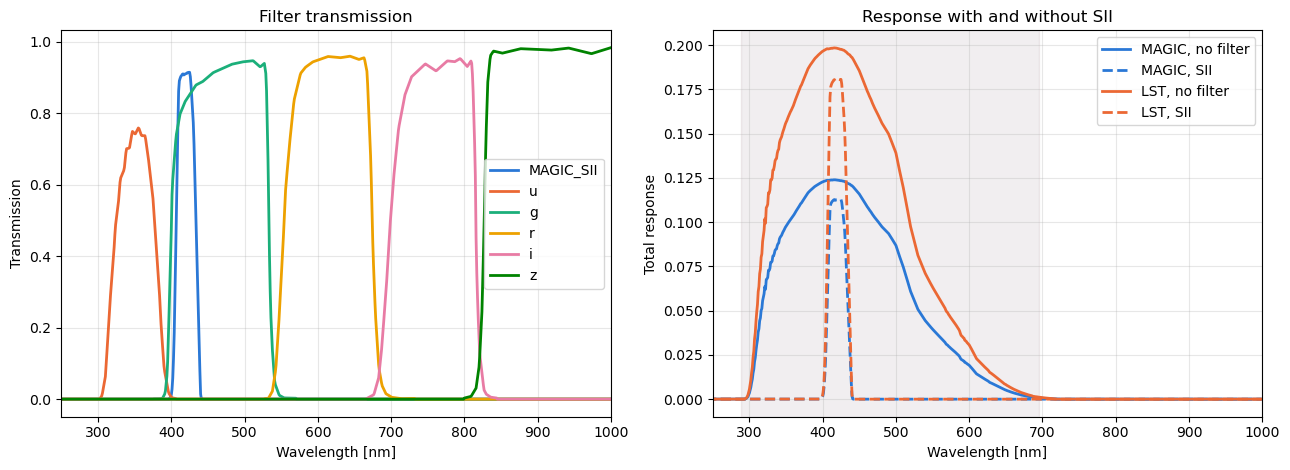

In [36]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for j, f in enumerate(["MAGIC_SII", "u", "g", "r", "i", "z"]):
    ax1.plot(WL, Instrument("MAGIC", filter_type=f, site=SITE).optical_filter_transmission(WL), lw=2,
             color=STEP_COLORS[j], label=f)
ax1.set(xlabel="Wavelength [nm]", ylabel="Transmission", title="Filter transmission", xlim=(250, 1000))
ax1.grid(alpha=0.3); ax1.legend()
for t in TELS:
    c = TEL_COLORS[t]
    ax2.plot(WL, response(INSTR[t]), color=c, lw=2, label=f"{t}, no filter")
    ax2.plot(WL, response(INSTR_SII[t]), color=c, lw=2, ls="--", label=f"{t}, SII")
    lo, hi, _ = INSTR[t].response_band()
    ax2.axvspan(lo, hi, color=c, alpha=0.06)
ax2.set(xlabel="Wavelength [nm]", ylabel="Total response", title="Response with and without SII", xlim=(250, 1000))
ax2.grid(alpha=0.3); ax2.legend()
plt.tight_layout()
plt.savefig(f"./Filter_transmission.png", dpi=200)
plt.show()

## 6 - Photons from the star
`Instrument.num_photons_from_mag` without a filter computes

N = t · A · ∫R(λ)dλ · Φ_Vega · 2.512^(−m),  with **Φ_Vega = 2020.2 ph cm⁻² s⁻¹ Å⁻¹** (`number_of_photons_from_Vega['QE']`),

i.e. one flat photon density over the whole response. The origin of 2020.2 is not documented; the ugriz values
(1539 ... 602) come from Martini's table and match CALSPEC. Here the same integral is done with the real Vega spectrum
(`data/alpha_lyr_stis_011.fits`, CALSPEC), which the package ships but does not use.

MAGIC: response-weighted Vega density = 1113 ph/cm2/s/A -> package star photons x 1.82
LST: response-weighted Vega density = 1113 ph/cm2/s/A -> package star photons x 1.82


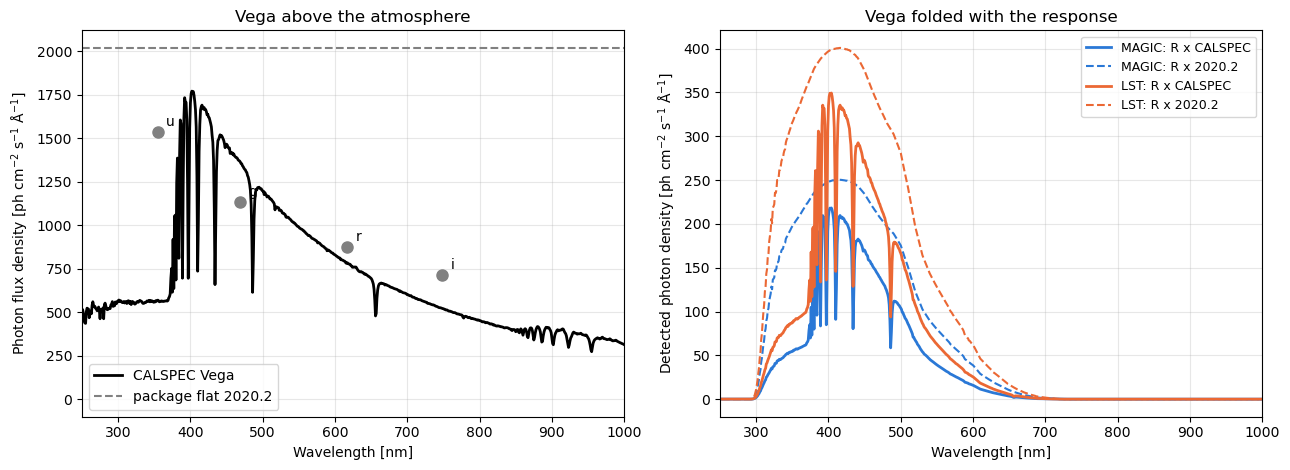

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(WL, VEGA_PH, color="k", lw=2, label="CALSPEC Vega")
ax1.axhline(INSTR["MAGIC"].number_of_photons_from_Vega["QE"], color="grey", ls="--", lw=1.5, label="package flat 2020.2")
for b, lam in [("u", 355), ("g", 469), ("r", 617), ("i", 748)]:
    ax1.plot(lam, INSTR["MAGIC"].number_of_photons_from_Vega[b], "o", ms=8, color="grey")
    ax1.annotate(b, (lam, INSTR["MAGIC"].number_of_photons_from_Vega[b]), textcoords="offset points", xytext=(6, 4))
ax1.set(xlabel="Wavelength [nm]", ylabel="Photon flux density [ph cm$^{-2}$ s$^{-1}$ Å$^{-1}$]", xlim=(250, 1000),
        title="Vega above the atmosphere")
ax1.grid(alpha=0.3); ax1.legend()

vega_ratio = {}
for t, i in INSTR.items():
    R = response(i)
    eff_density = trapz(R * VEGA_PH, WL) / trapz(R, WL)
    vega_ratio[t] = i.number_of_photons_from_Vega["QE"] / eff_density
    ax2.plot(WL, R * VEGA_PH, color=TEL_COLORS[t], lw=2, label=f"{t}: R x CALSPEC")
    ax2.plot(WL, R * i.number_of_photons_from_Vega["QE"], color=TEL_COLORS[t], lw=1.5, ls="--", label=f"{t}: R x 2020.2")
    print(f"{t}: response-weighted Vega density = {eff_density:.0f} ph/cm2/s/A -> package star photons x {vega_ratio[t]:.2f}")
ax2.set(xlabel="Wavelength [nm]", ylabel="Detected photon density [ph cm$^{-2}$ s$^{-1}$ Å$^{-1}$]",
        xlim=(250, 1000), title="Vega folded with the response")
ax2.grid(alpha=0.3); ax2.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"./Vega_photons.png", dpi=200)
plt.show()

**Vega photons for every filter.** The same check for every entry of `number_of_photons_from_Vega`, all in
ph cm⁻² s⁻¹ Å⁻¹ at magnitude 0 (CALSPEC is scaled from m = 0.03 to 0):
- *dictionary*: the package value, used as a flat density over the response.
- *CALSPEC, filter only*: Vega weighted by the filter curve alone (as in Martini's table), on the filter file's own grid.
- *AB 0 mag, filter only*: the same for a 3631 Jy source. The ugriz dictionary values match this column, so they are
  **AB** zero points, not Vega ones (largest effect in u, where Vega is ~0.9 mag fainter than AB 0).
- *CALSPEC, &lt;tel&gt; response*: Vega weighted by filter × atmosphere × telescope, the like-for-like number for
  `num_photons_from_mag`; *dict / CALSPEC* is the factor by which the package's star photons are off with that filter.

`QE` has no filter file (no filter); `MAGIC_QE` is the same curve as a filter. z is NaN with the response because the
detector QE is zero above ~800 nm. `MAGIC_SII` is the 400–440 nm intensity-interferometry filter.

In [38]:
# Vega photon density per filter: package dictionary vs CALSPEC Vega (and AB 0 mag), all in ph cm^-2 s^-1 A^-1 at mag 0
H_CGS, C_CGS = 6.62607e-27, 2.99792e10
MAG0 = 10 ** (0.4 * VEGA_MAG)                                   # CALSPEC Vega is m = 0.03: scale to m = 0


def ab_photon_density(wl_nm):
    """AB magnitude 0 (3631 Jy) photon flux density [ph cm^-2 s^-1 A^-1]."""
    return 3631e-23 / (H_CGS * np.asarray(wl_nm) * 1e-7) * 1e-8     # per cm -> per A


def filter_weighted(key, density):
    """Density weighted by the filter curve alone, on the file's own grid (no truncation at 999 nm)."""
    lam, T = np.loadtxt(f"{PACKAGE_DATA}/optical_filters/optical_filter_{key}.txt", unpack=True)
    return trapz(T * density(lam), lam) / trapz(T, lam)


vega_dict = INSTR["MAGIC"].number_of_photons_from_Vega
rows = {}
for key, phi_dict in vega_dict.items():
    row = {"dictionary": phi_dict}
    has_file = key != "QE"
    row["CALSPEC, filter only"] = filter_weighted(key, vega_photon_density) * MAG0 if has_file else np.nan
    row["AB 0 mag, filter only"] = filter_weighted(key, ab_photon_density) if has_file else np.nan
    for t in TELS:
        R = response(Instrument(t, filter_type=key, site=SITE) if has_file else INSTR[t])
        phi = trapz(R * VEGA_PH, WL) / trapz(R, WL) * MAG0
        row[f"CALSPEC, {t} response"] = phi
        row[f"dict / CALSPEC ({t})"] = phi_dict / phi
    rows[key] = row
vega_filters = pd.DataFrame(rows).T
vega_filters.round(2)

,dictionary,"CALSPEC, filter only","AB 0 mag, filter only","CALSPEC, MAGIC response",dict / CALSPEC (MAGIC),"CALSPEC, LST response",dict / CALSPEC (LST)
u,1539.30,620.61,1566.15,661.60,2.33,661.60,2.33
g,1134.60,1313.35,1177.13,1387.05,0.82,1387.05,0.82
r,875.40,799.02,893.96,885.53,0.99,885.53,0.99
i,714.50,524.60,724.60,621.74,1.15,621.74,1.15
z,602.20,349.22,573.31,NaN,NaN,NaN,NaN
MAGIC_SII,356.00,1552.43,1304.43,1552.49,0.23,1552.49,0.23
QE,2020.20,NaN,NaN,1143.97,1.77,1143.97,1.77
MAGIC_QE,2020.20,997.60,1430.66,1147.97,1.76,1147.97,1.76
gaia_bp,9.73,1094.56,1087.74,1258.51,0.01,1258.51,0.01


**Star colour.** The package also assumes the star's magnitude in this broad band equals its B magnitude (Vega
colours). For B5–B9.5 stars, a blackbody of 10 000–15 000 K normalised to the same B magnitude (Bessell B, approximate)
gives the colour correction below (cf. old notebook cell 27, which folded blackbodies with the response).

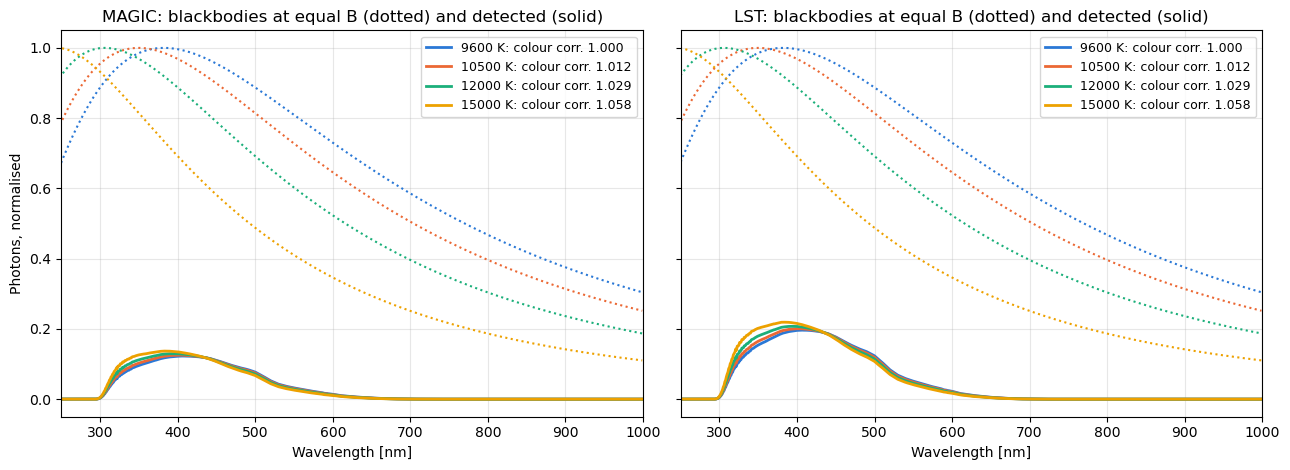

In [13]:
fig, axes = tel_axes(sharey=True)
temps = [9600, 10500, 12000, 15000]
for ax, (t, i) in zip(axes, INSTR.items()):
    R = response(i)
    for T, c in zip(temps, STEP_COLORS):
        spec = bb_photons(WL, T) / trapz(BESSELL_B * bb_photons(WL, T), WL)     # same B-band photons
        ax.plot(WL, spec / spec.max(), color=c, lw=1.5, ls=":")
        ax.plot(WL, spec * R / (bb_photons(WL, 9600) / trapz(BESSELL_B * bb_photons(WL, 9600), WL)).max(), color=c, lw=2,
                label=f"{T} K: colour corr. {colour_correction(i, T):.3f}")
    ax.set(xlabel="Wavelength [nm]", title=f"{t}: blackbodies at equal B (dotted) and detected (solid)", xlim=(250, 1000))
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
axes[0].set_ylabel("Photons, normalised")
plt.tight_layout()
plt.savefig(f"./BlackBody_photons.png", dpi=200)
plt.show()

**Three ways to count the star photons** (old notebook cells 36–40 compared the first two): the package (flat Vega
density), the CALSPEC integral (with the 12 000 K colour correction as a dashed line), and the old blackbody + Roach
formula, N = 6.85·10¹⁴·10^(−0.4m)/T ph m⁻² s⁻¹ times the fraction of blackbody energy in the response.

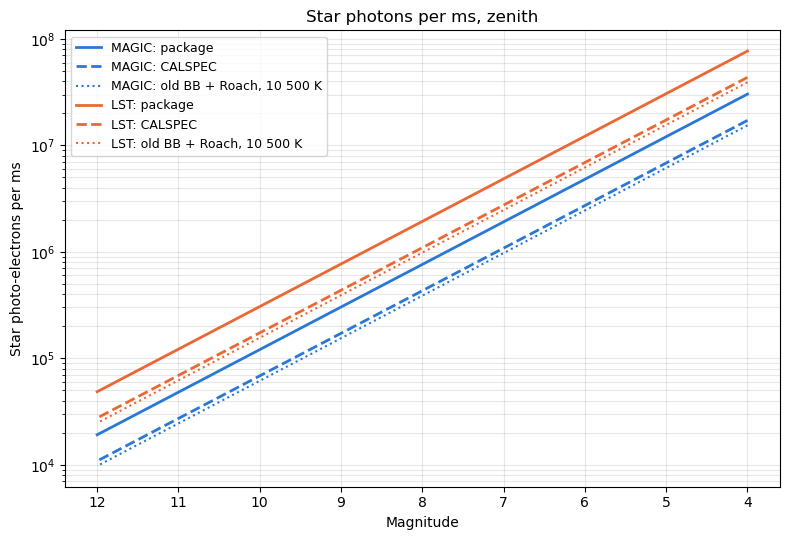

,MAGIC,LST
p.e. per ms at m = 7.0,,
package,1.912e+06,4.851e+06
CALSPEC (Vega colour),1.083e+06,2.748e+06
CALSPEC x colour(12 000 K),1.115e+06,2.829e+06
old BB + Roach (10 500 K),9.734e+05,2.469e+06


In [14]:
SIGMA_SB = 5.670374e-8

def photons_old_blackbody(instr, mag, t_ms, T):
    """Old notebook photons_for_obs_time: Roach formula x fraction of B_lambda energy inside the response (100-800 nm)."""
    lam = WL[WL < 800]
    B_lam = 2 * 6.626e-34 * 3e8 ** 2 / ((lam * 1e-9) ** 5 * np.expm1(6.626e-34 * 3e8 / (lam * 1e-9 * 1.38e-23 * T)))
    fraction = trapz(B_lam * response(instr)[WL < 800], lam) / (SIGMA_SB * T ** 4 / np.pi * 1e9)
    return fraction * 6.85e14 * 10 ** (-0.4 * np.asarray(mag)) / T * instr.mirror_area_per_telescope[instr.telescope_type] * t_ms * 1e-3

fig, ax = plt.subplots(figsize=(8, 5.5))
mags = np.linspace(4, 12, 33)
tab = {}
for t, i in INSTR.items():
    c = TEL_COLORS[t]
    pkg = i.num_photons_from_mag(1.0, mags)
    cal = star_photons_calspec(i, mags, 1.0)
    ax.plot(mags, pkg, color=c, lw=2, label=f"{t}: package")
    ax.plot(mags, cal, color=c, lw=2, ls="--", label=f"{t}: CALSPEC")
    ax.plot(mags, photons_old_blackbody(i, mags, 1.0, 10500), color=c, lw=1.5, ls=":", label=f"{t}: old BB + Roach, 10 500 K")
    tab[t] = {"package": i.num_photons_from_mag(1.0, REF_MAG), "CALSPEC (Vega colour)": star_photons_calspec(i, REF_MAG, 1.0),
              "CALSPEC x colour(12 000 K)": star_photons_calspec(i, REF_MAG, 1.0, teff=12000),
              "old BB + Roach (10 500 K)": photons_old_blackbody(i, REF_MAG, 1.0, 10500)}
ax.set(yscale="log", xlabel="Magnitude", ylabel="Star photo-electrons per ms", title="Star photons per ms, zenith")
ax.invert_xaxis(); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"./Star_photoelectrons_ms.png", dpi=200)
plt.show()
pd.DataFrame(tab).rename_axis(f"p.e. per ms at m = {REF_MAG}")

## 7 - Night-sky background
Benn & Ellison La Palma spectrum (normalised to 0.24 ph cm⁻² ns⁻¹ sr⁻¹ in 300–650 nm) and the half-moon version
(old notebook cell 32). The rate per pixel is ∑ flux(λ) · T_tel(λ) · A · Ω_pixel with 1 nm steps, no atmosphere (the
spectrum is measured at the ground) and no airmass dependence.

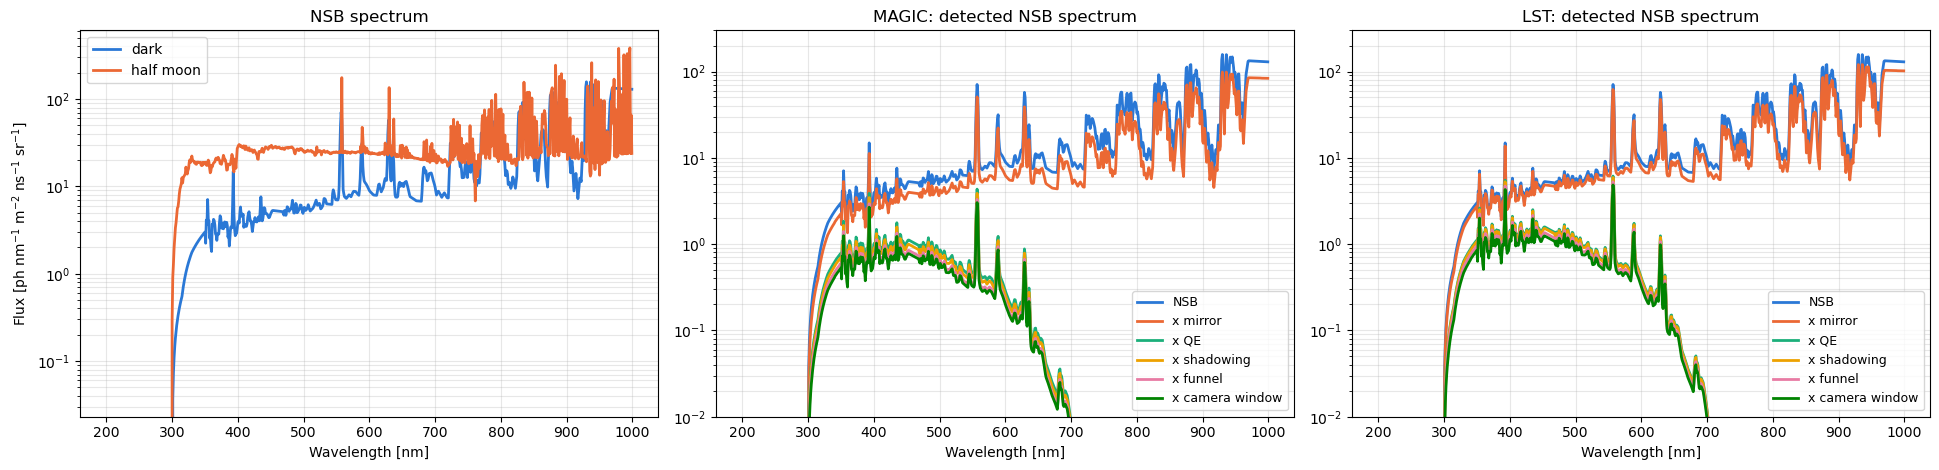

,MAGIC,LST
"package, dark [ph/ns/pixel]",0.098,2.579e-01
"package, half moon",0.479,1.264e+00
"package, dark, SII filter",0.010,2.709e-02
hard-coded dict (unused),0.098,2.652e-01
old notebook printout,NaN,2.579e-01
dark x hexagonal pixel (notebook),0.108,2.844e-01
NSB p.e. per 10 ms bin,977074.407,2.579e+06


In [15]:
dark = Instrument.nsb_spectrum(False); moon = Instrument.nsb_spectrum(True)
lam_nsb = np.asarray(dark["wavelength(nm)"], float)
fig, axes = plt.subplots(1, 1 + len(TELS), figsize=(6.5 * (1 + len(TELS)), 4.8))
axes[0].plot(lam_nsb, dark["flux"], color=STEP_COLORS[0], lw=2, label="dark")
axes[0].plot(moon["wavelength(nm)"], moon["flux"], color=STEP_COLORS[1], lw=2, label="half moon")
axes[0].set(yscale="log", xlabel="Wavelength [nm]", ylabel="Flux [ph nm$^{-1}$ m$^{-2}$ ns$^{-1}$ sr$^{-1}$]", title="NSB spectrum")
axes[0].grid(alpha=0.3, which="both"); axes[0].legend()
for ax, (t, i) in zip(axes[1:], INSTR.items()):
    steps = [("NSB", np.asarray(dark["flux"], float)), ("x mirror", i.mirror_reflectivity(lam_nsb)),
             ("x QE", i.quantum_efficiency(lam_nsb)), ("x shadowing", i.transmission_per_telescope[t] + 0 * lam_nsb),
             ("x funnel", i.funnel_transmission_per_telescope[t] + 0 * lam_nsb), ("x camera window", i.camera_transmission(lam_nsb))]
    cum = np.ones_like(lam_nsb)
    for (lab, f), c in zip(steps, STEP_COLORS):
        cum = cum * f
        ax.plot(lam_nsb, cum, color=c, lw=2, label=lab)
    ax.set(yscale="log", ylim=(1e-2, 300), xlabel="Wavelength [nm]", title=f"{t}: detected NSB spectrum")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"./NSB_Spectrum.png", dpi=200)
plt.show()

nsb_rates = pd.DataFrame({t: {
    "package, dark [ph/ns/pixel]": i.number_nsb_photons(),
    "package, half moon": i.number_nsb_photons(moon=True),
    "package, dark, SII filter": INSTR_SII[t].number_nsb_photons(),
    "hard-coded dict (unused)": i.nsb_per_telescope[t],
    "old notebook printout": {"LST": 0.25789, "MST-N": 0.23661}.get(t, np.nan),
    "dark x hexagonal pixel (notebook)": i.number_nsb_photons() * HEX_OVER_CIRCLE,
    "NSB p.e. per 10 ms bin": i.number_nsb_photons() * REF_BIN.to_value(u.ns)} for t, i in INSTR.items()})
nsb_rates

## 8 - PSF: how much of the star falls in one pixel
The package puts 100 % of the star light in the target pixel. The logged PSFs (`elog_notes`, mm on the camera) are
the MAGIC 39 % containment value and the LST-1 D80. For a 2D Gaussian the 39 % containment radius is σ, so the MAGIC
value is read as the 39 % containment **diameter** (σ = PSF/2, the usual MAGIC convention); σ = PSF is shown as the
pessimistic reading. LST-1: σ = D80 / (2 × 1.794). The pixel is a hexagon of flat-to-flat = pixel FoV × focal length
(MAGIC 17 m, LST 28 m) and the star is assumed centred, so these are upper limits (mispointing lowers them).

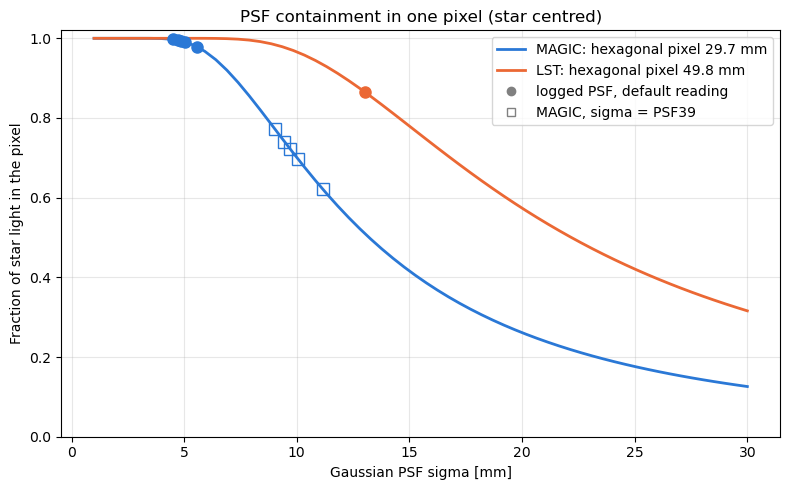

logged PSF [mm]  sigma [mm]  pixel [mm]  containment
night      telescope reading                                                               
2025-12-16 MAGIC-2   sigma = PSF39/2             10.07       5.035      29.671        0.991
                     sigma = PSF39               10.07      10.070      29.671        0.696
2026-03-08 MAGIC-1   sigma = PSF39/2              9.45       4.725      29.671        0.995
                     sigma = PSF39                9.45       9.450      29.671        0.741
           MAGIC-2   sigma = PSF39/2              9.02       4.510      29.671        0.997
                     sigma = PSF39                9.02       9.020      29.671        0.773
2026-08-19 MAGIC-1   sigma = PSF39/2             11.15       5.575      29.671        0.979
                     sigma = PSF39               11.15      11.150      29.671        0.622
           MAGIC-2   sigma = PSF39/2              9.71       4.855      29.671        0.994
                     sigma = PSF39                9.71       9.710      29.671        0.722
           LST-1     sigma = D80/3.59            46.69      13.012      49.847        0.866

In [16]:
psf_rows = []
for night in log.select():
    for dc_key, value in (night.elog_notes or {}).items():
        tel_name = next(t.name for t in config.ORM_ARRAY.telescopes if t.dc_key == dc_key)
        kind = KIND[tel_name]
        if kind == "MAGIC":
            readings = {"sigma = PSF39/2": value / 2, "sigma = PSF39": value}
        else:
            readings = {"sigma = D80/3.59": value / (2 * R80_OVER_SIGMA)}
        for reading, sigma in readings.items():
            psf_rows.append({"night": night.name, "telescope": tel_name, "logged PSF [mm]": value, "reading": reading,
                             "sigma [mm]": sigma, "pixel [mm]": pixel_flat_mm(kind),
                             "containment": hex_pixel_containment(sigma, pixel_flat_mm(kind))})
psf_table = pd.DataFrame(psf_rows).set_index(["night", "telescope", "reading"])

# containment used downstream: default reading; nights without a PSF take the telescope's median
default_reading = psf_table.reset_index().query("reading != 'sigma = PSF39'")
PSF_CONTAINMENT = {(r.night, r.telescope): r.containment for r in default_reading.itertuples()}
PSF_MEDIAN = default_reading.groupby("telescope")["containment"].median().to_dict()
def psf_containment(night_name, tel_name):
    return PSF_CONTAINMENT.get((night_name, tel_name), PSF_MEDIAN.get(tel_name, 1.0))

fig, ax = plt.subplots(figsize=(8, 5))
sig = np.linspace(1, 30, 60)
for t in ["MAGIC", "LST"]:
    ax.plot(sig, [hex_pixel_containment(s, pixel_flat_mm(t)) for s in sig], color=TEL_COLORS[t], lw=2,
            label=f"{t}: hexagonal pixel {pixel_flat_mm(t):.1f} mm")
for (night, tel, reading), r in psf_table.iterrows():
    ax.plot(r["sigma [mm]"], r["containment"], "o" if reading != "sigma = PSF39" else "s", ms=8,
            mfc="none" if reading == "sigma = PSF39" else TEL_COLORS[KIND[tel]], mec=TEL_COLORS[KIND[tel]])
ax.plot([], [], "o", color="grey", label="logged PSF, default reading"); ax.plot([], [], "s", mfc="none", mec="grey", label="MAGIC, sigma = PSF39")
ax.set(xlabel="Gaussian PSF sigma [mm]", ylabel="Fraction of star light in the pixel", title="PSF containment in one pixel (star centred)", ylim=(0, 1.02))
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f"./PSF_containment.png", dpi=200)
plt.show()
psf_table

## 9 - A check that does not need the absolute calibration: NSB / star
The fast signal is a variance, which is linear in the photon rate, so the ratio of the dark-run level to the
NSB-subtracted star level is the ratio of NSB to star photons in the pixel, whatever the gain. The theory gives the
same ratio with no free parameter. Caveat: the dark-run level also contains the electronic pedestal (the variance of
the electronics with no light), so the measured ratio is an upper limit on NSB/star.

In [18]:
nsb

dc_key  nsb_dark  nsb_dark_err  dc_scale  nsb_dc_bkg_dc  nsb_dc_hist_dc  nsb_dc_bkg  nsb_dc_hist  nsb_default nsb_source  star_mean
night      observation telescope                                                                                                                                    
2025-12-16 HD-4335     MAGIC-2       m2     8.121         0.028    19.646          0.309           0.027       6.080        0.537        8.121       dark     59.248
           HD-8837     MAGIC-2       m2     8.121         0.028    20.228          0.312           0.027       6.310        0.553        8.121       dark     38.613
           HD-22353    MAGIC-2       m2     8.121         0.028    20.838          0.387           0.027       8.070        0.570        8.121       dark     27.011
           HD-17316    MAGIC-2       m2     8.121         0.028    21.870          0.368           0.027       8.044        0.598        8.121       dark     21.107
           HD-20920    MAGIC-2       m2     8.121         0.028    22.066          0.345           0.027       7.617        0.604        8.121       dark     18.407
2026-03-08 HD-40626    MAGIC-2       m2       NaN         0.000    18.773          0.386           0.276       7.251        5.173        7.251     dc_bkg     56.330
           HD-45563    MAGIC-2       m2       NaN         0.000    18.425          0.436           0.276       8.027        5.077        8.027     dc_bkg     36.946
           HD-46016    MAGIC-2       m2       NaN         0.000    19.420          0.367           0.276       7.137        5.351        7.137     dc_bkg     26.127
           HD-40626    LST-1       lst1       NaN         0.000     5.729          8.104           2.281      46.428       13.068       13.068    dc_hist     78.649
           HD-45563    LST-1       lst1       NaN         0.000     5.919         10.979           2.281      64.987       13.502       13.502    dc_hist     61.948
           HD-46016    LST-1       lst1       NaN         0.000     5.943          7.720           2.281      45.879       13.556       13.556    dc_hist     56.799
           HD-40626    MAGIC-1       m1       NaN         0.000     4.251          0.541           0.542       2.298        2.305        2.298     dc_bkg     11.986
           HD-45563    MAGIC-1       m1       NaN         0.000     4.306          0.614           0.542       2.642        2.335        2.642     dc_bkg      9.057
           HD-46016    MAGIC-1       m1       NaN         0.000     4.475          0.530           0.542       2.374        2.426        2.374     dc_bkg      6.259
2026-08-19 HD170263    MAGIC-2       m2     6.526         0.022    23.325          0.346           0.017       8.061        0.400        6.526       dark     10.733
           HD176914    MAGIC-2       m2     6.526         0.022    18.704          0.420           0.017       7.856        0.321        6.526       dark     26.396
           HD196243    MAGIC-2       m2     6.526         0.022    19.622          0.410           0.017       8.054        0.337        6.526       dark     20.511
           HD199102    MAGIC-2       m2     6.526         0.022    22.130          0.331           0.017       7.327        0.380        6.526       dark     14.566
           HD170263    LST-1       lst1    13.029         0.078     6.098          7.413           0.135      45.209        0.820       13.029       dark     15.835
           HD176914    LST-1       lst1    13.029         0.078     5.878          8.159           0.135      47.957        0.791       13.029       dark     34.570
           HD196243    LST-1       lst1    13.029         0.078     5.772          8.321           0.135      48.027        0.776       13.029       dark     30.875
           HD199102    LST-1       lst1    13.029         0.078     5.790          7.573           0.135      43.848        0.779       13.029       dark     21.965
           HD170263    MAGIC-1       m1     2.493         0.008     5.044

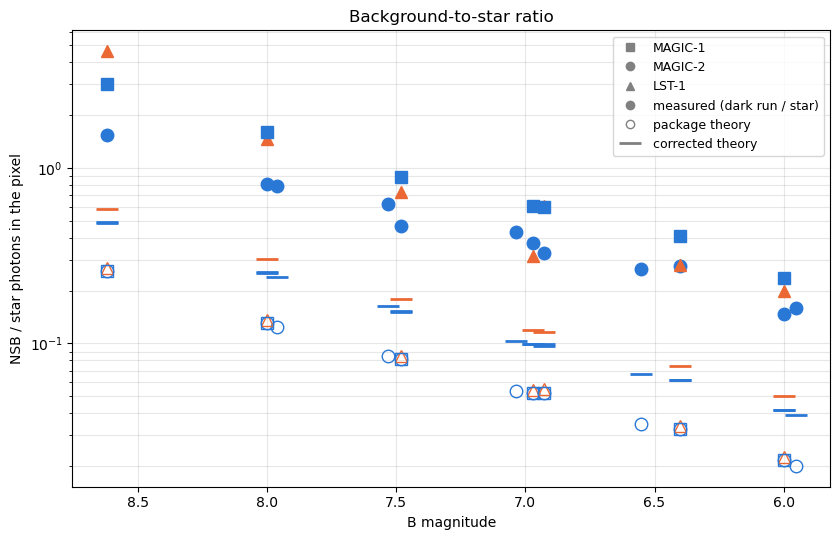

,measured / package,measured / corrected
telescope,,
LST-1,8.869,4.050
MAGIC-1,11.680,6.111
MAGIC-2,7.013,3.671


In [17]:
lcs = load_lightcurves(log)
nsb = nsb_table(log, lcs=lcs)
bs_rows = []
for (night_name, obs_name, tel_name), r in nsb.iterrows():
    obs = log.nights[night_name].observations[obs_name]
    i = INSTR[KIND[tel_name]]
    X = conditions["airmass_mean"].get((night_name, obs_name), 1.0)
    mirrors = throughput_from_faulty_panels(obs.faulty_mirrors.get(DC_KEY[tel_name]), DC_KEY[tel_name])
    pkg = package_budget(i, obs.magnitude(BAND), 1 * u.ms, airmass=X, extinction=True, throughput_factor=mirrors)
    cor = corrected_budget(i, obs.magnitude(BAND), 1 * u.ms, airmass=X, throughput=mirrors,
                           psf=psf_containment(night_name, tel_name), teff=teff_from_spectral_type(obs.spectral_type))
    bs_rows.append({"night": night_name, "observation": obs_name, "telescope": tel_name, "mag": obs.magnitude(BAND),
                    "nsb_source": r["nsb_source"],
                    "measured": r["nsb_default"] / (r["star_mean"] - r["nsb_default"]),
                    "package": pkg["nsb_photons"] / pkg["star_photons"],
                    "corrected": cor["nsb_photons"] / cor["star_photons"]})
bs = pd.DataFrame(bs_rows).set_index(["night", "observation", "telescope"])
bs["measured / package"] = bs["measured"] / bs["package"]
bs["measured / corrected"] = bs["measured"] / bs["corrected"]

MARK = {"MAGIC-1": "s", "MAGIC-2": "o", "LST-1": "^"}
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for (night_name, obs_name, tel_name), r in bs.iterrows():
    c = TEL_COLORS[KIND[tel_name]]
    ax.plot(r["mag"], r["measured"], MARK[tel_name], ms=9, color=c)
    ax.plot(r["mag"], r["package"], MARK[tel_name], ms=9, mfc="none", mec=c)
    ax.plot(r["mag"], r["corrected"], "_", ms=16, mew=2, color=c)
handles = [plt.Line2D([], [], color="grey", marker=m, ls="", label=t) for t, m in MARK.items()]
handles += [plt.Line2D([], [], color="grey", marker="o", ls="", label="measured (dark run / star)"),
            plt.Line2D([], [], color="grey", marker="o", mfc="none", ls="", label="package theory"),
            plt.Line2D([], [], color="grey", marker="_", ms=16, mew=2, ls="", label="corrected theory")]
ax.set(yscale="log", xlabel=f"{BAND} magnitude", ylabel="NSB / star photons in the pixel", title="Background-to-star ratio")
ax.invert_xaxis(); ax.grid(alpha=0.3, which="both"); ax.legend(handles=handles, fontsize=9)
plt.tight_layout()
plt.savefig(f"./NSB_to_star_ratio.png", dpi=200)
plt.show()
bs.groupby("telescope")[["measured / package", "measured / corrected"]].median()

## 10 - Photon counts per bin
Star photo-electrons for B = 6, 7, 8, 9 against the NSB count B, √B and 5√B (old notebook cells 42, 45, 51), package
model, zenith. Vertical lines: one fast-photometry frame (0.524 ms) and the 5 / 10 / 100 ms bins of the SNR study.

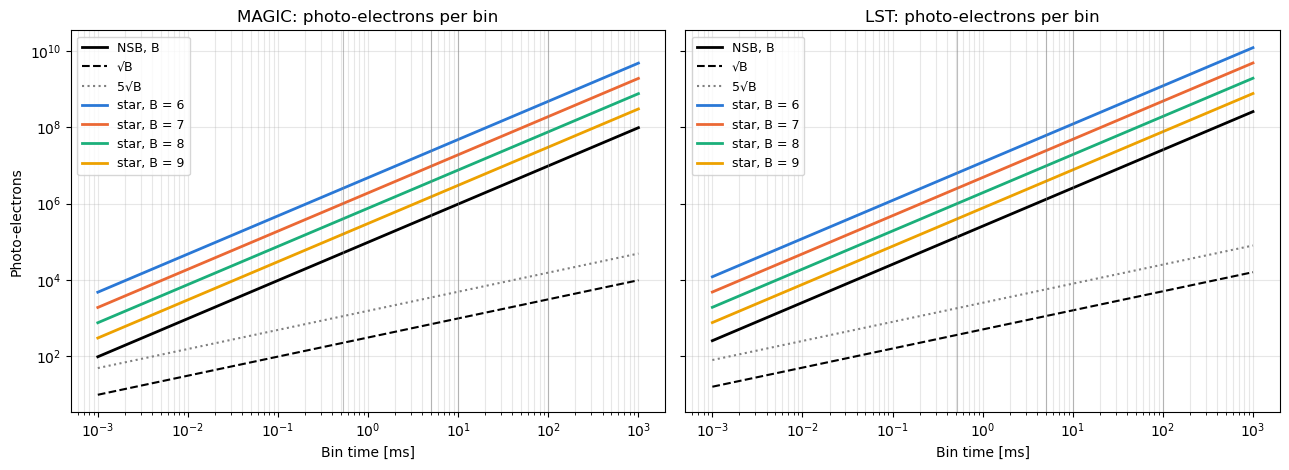

In [19]:
fig, axes = tel_axes(sharey=True)
for ax, (t, i) in zip(axes, INSTR.items()):
    B = i.number_nsb_photons() * BIN_MS * 1e6
    ax.plot(BIN_MS, B, color="k", lw=2, label="NSB, B")
    ax.plot(BIN_MS, np.sqrt(B), color="k", lw=1.5, ls="--", label="√B")
    ax.plot(BIN_MS, 5 * np.sqrt(B), color="grey", lw=1.5, ls=":", label="5√B")
    for m, c in zip([6, 7, 8, 9], STEP_COLORS):
        ax.plot(BIN_MS, i.num_photons_from_mag(BIN_MS, m), color=c, lw=2, label=f"star, B = {m}")
    for tb in [FRAME_SAMPLES_DURATION_S * 1e3, 5, 10, 100]:
        ax.axvline(tb, color="grey", lw=0.8, alpha=0.5)
    ax.set(xscale="log", yscale="log", xlabel="Bin time [ms]", title=f"{t}: photo-electrons per bin")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
axes[0].set_ylabel("Photo-electrons")
plt.tight_layout()
plt.savefig(f"./Photons_per_time_stars_NSB.png", dpi=200)
plt.show()

## 11 - The noise budget term by term
`Instrument.noise_budget` adds in quadrature (fractions of the star signal S):

| term | package | notebook correction |
|---|---|---|
| shot | F²(S+B)/S², F = 1.15 | same form, S from CALSPEC, B × 1.103 (hexagon) |
| electronic | 0.7²/S², as if one 0.7 p.e. readout per bin | kept, but doubtful for a variance signal: the electronics add a pedestal (subtracted) and enter the floor |
| scintillation | 10e-6 · 1.5² · **D_cm**^(−4/3) · X³ · e^(−2h/H) / (2t) | Osborn+2015 eq. 7 is in SI (**D in m**) with t⁻¹; plus the short-exposure saturation for t ≲ D/v |
| variance floor | 2k/N per frame / n_frames, k = 2 (MAGIC), 0 (LST) | × ((S+B)/S)²: the variance estimator's error is relative to the whole variance |
| red noise | input `red_noise_rms` (0 here) | — |

The floor is the radiometer equation: a variance estimated from N samples of a signal of bandwidth b has relative
error √(2/(2 b T)). With 2 ns samples (Nyquist 250 MHz) and b = 110 MHz (`b_v` in MAGIC-LST.yml), k = 250/110 = 2.27,
next to the k ≈ 2 measured on MAGIC.

radiometer k = Nyquist / bandwidth = 2.27 (b_v = 110 MHz)


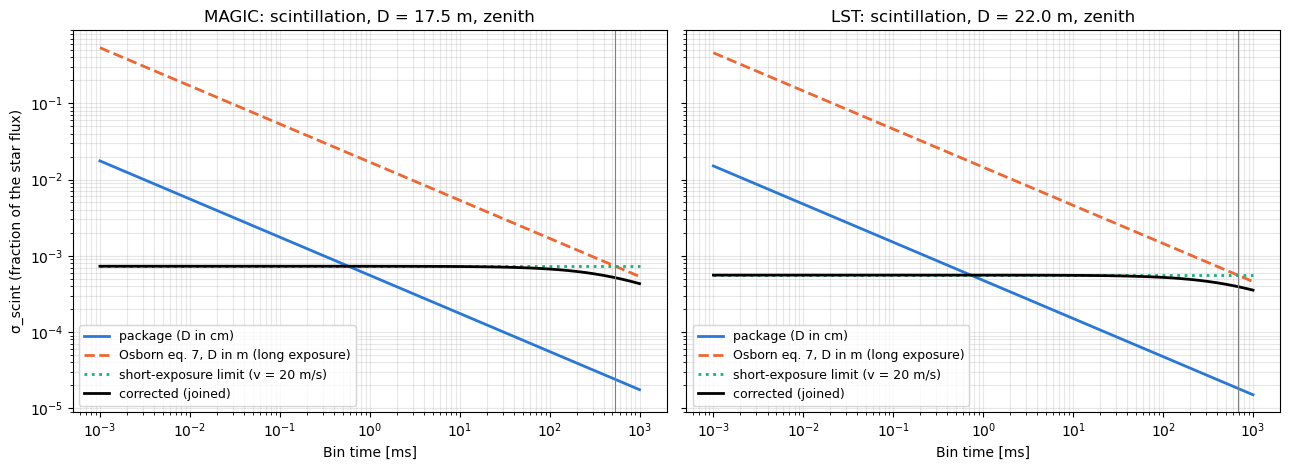

In [20]:
print("radiometer k = Nyquist / bandwidth = %.2f (b_v = %.0f MHz)" % (250e6 / float(II["b_v"][0]), float(II["b_v"][0]) / 1e6))

fig, axes = tel_axes(sharey=True)
for ax, (t, i) in zip(axes, INSTR.items()):
    D = aperture_m(i)
    pkg = np.array([package_budget(i, REF_MAG, tb * u.ms)["sigma_scint"] for tb in BIN_MS])
    ax.plot(BIN_MS, pkg, color=STEP_COLORS[0], lw=2, label="package (D in cm)")
    ax.plot(BIN_MS, scint_long(D, BIN_MS * 1e-3, 1, i.site_altitude_m), color=STEP_COLORS[1], lw=2, ls="--",
            label="Osborn eq. 7, D in m (long exposure)")
    ax.plot(BIN_MS, scint_short(D, 1, i.site_altitude_m) + 0 * BIN_MS, color=STEP_COLORS[2], lw=2, ls=":",
            label=f"short-exposure limit (v = {WIND_MS:.0f} m/s)")
    ax.plot(BIN_MS, scint_corrected(D, BIN_MS * 1e-3, 1, i.site_altitude_m), color="k", lw=2, label="corrected (joined)")
    ax.axvline(0.615 * D / WIND_MS * 1e3, color="grey", lw=0.8)
    ax.set(xscale="log", yscale="log", xlabel="Bin time [ms]", title=f"{t}: scintillation, D = {D:.1f} m, zenith")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
axes[0].set_ylabel("σ_scint (fraction of the star flux)")
plt.tight_layout()
plt.savefig(f"./Scintillation_noise.png", dpi=200)
plt.show()

All terms against bin time for a B = 7 star at the zenith (solid: package, dashed: corrected). The grey dotted line
is the old notebook's √(S+B)/S (cells 55–57).

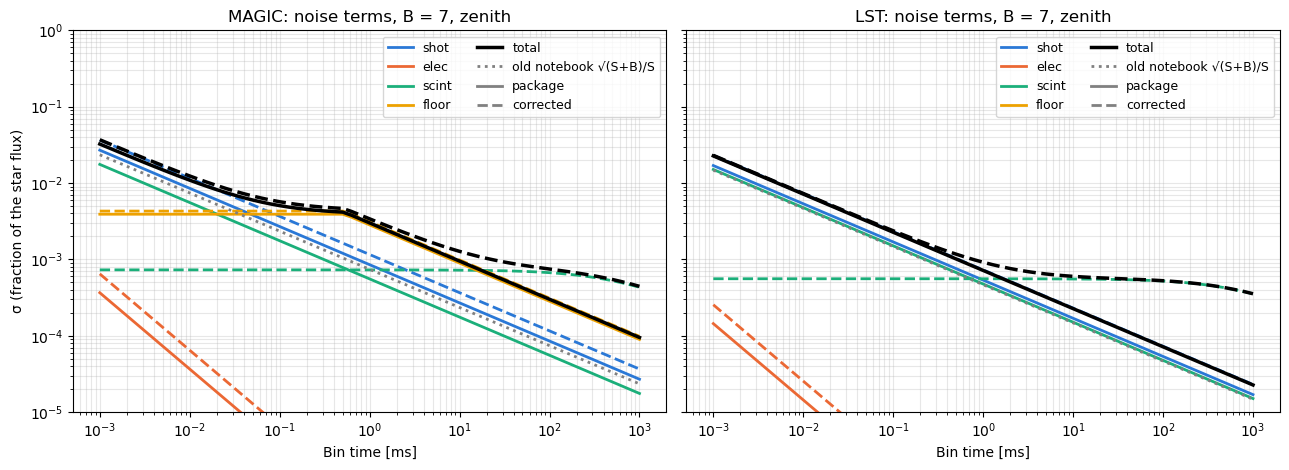

In [21]:
TERMS = ["shot", "elec", "scint", "floor", "total"]
fig, axes = tel_axes(sharey=True)
for ax, (t, i) in zip(axes, INSTR.items()):
    pkg = [package_budget(i, REF_MAG, tb * u.ms) for tb in BIN_MS]
    cor = [corrected_budget(i, REF_MAG, tb * u.ms) for tb in BIN_MS]
    for term, c in zip(TERMS, STEP_COLORS):
        key = f"sigma_{term}"
        ax.plot(BIN_MS, [p[key] for p in pkg], color=c if term != "total" else "k", lw=2.5 if term == "total" else 2, label=f"{term}")
        ax.plot(BIN_MS, [p[key] for p in cor], color=c if term != "total" else "k", lw=2.5 if term == "total" else 2, ls="--")
    shot_only = [np.sqrt(p["star_photons"] + p["nsb_photons"]) / p["star_photons"] for p in pkg]
    ax.plot(BIN_MS, shot_only, color="grey", ls=":", lw=2, label="old notebook √(S+B)/S")
    ax.plot([], [], color="grey", lw=2, label="package"); ax.plot([], [], color="grey", lw=2, ls="--", label="corrected")
    ax.set(xscale="log", yscale="log", ylim=(1e-5, 1), xlabel="Bin time [ms]", title=f"{t}: noise terms, B = {REF_MAG:g}, zenith")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9, ncol=2)
axes[0].set_ylabel("σ (fraction of the star flux)")
plt.tight_layout()
plt.savefig(f"./All_noise.png", dpi=200)
plt.show()

The same against magnitude at the 5, 10 and 100 ms bins of the SNR study.

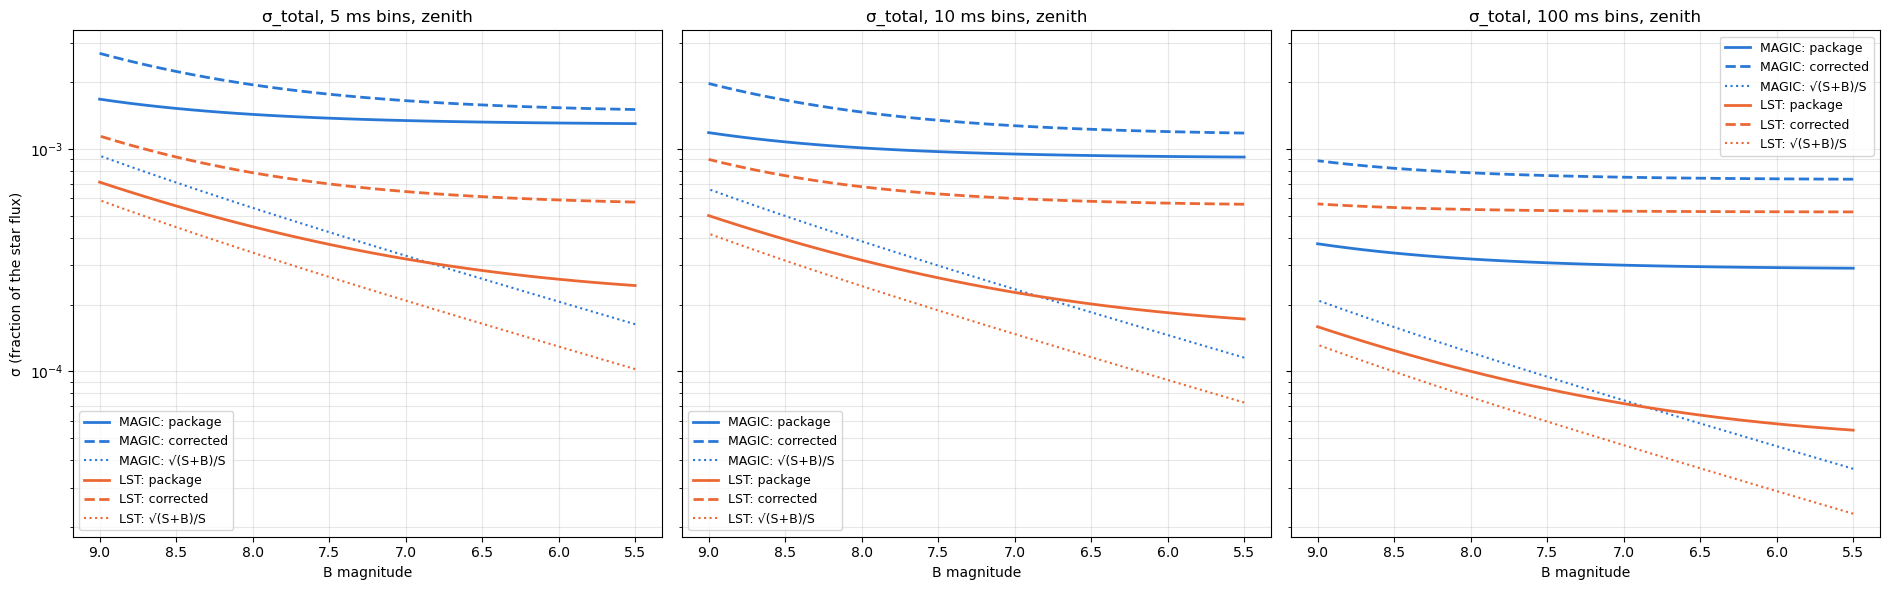

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharey=True)
for ax, tb in zip(axes, [5 * u.ms, 10 * u.ms, 100 * u.ms]):
    for t, i in INSTR.items():
        c = TEL_COLORS[t]
        ax.plot(MAG_GRID, package_budget(i, MAG_GRID, tb)["sigma_total"], color=c, lw=2, label=f"{t}: package")
        ax.plot(MAG_GRID, corrected_budget(i, MAG_GRID, tb)["sigma_total"], color=c, lw=2, ls="--", label=f"{t}: corrected")
        ax.plot(MAG_GRID, package_budget(i, MAG_GRID, tb)["sigma_shot"] / i.excess_noise_factor_per_telescope[t],
                color=c, lw=1.5, ls=":", label=f"{t}: √(S+B)/S")
    ax.set(yscale="log", xlabel=f"{BAND} magnitude", title=f"σ_total, {tb:g} bins, zenith")
    ax.invert_xaxis(); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
axes[0].set_ylabel("σ (fraction of the star flux)")
plt.tight_layout()
plt.savefig(f"./Final noise_5ms_10ms_100ms.png", dpi=200)
plt.show()

## 12 - Limiting magnitude
Faintest star seen at 5σ in a single bin (old notebook cell 52 used S = 5√B, i.e. NSB-only), with no filter and with
SII. `noise_budget` takes an array of magnitudes, so each curve is an interpolation on a fine magnitude grid.

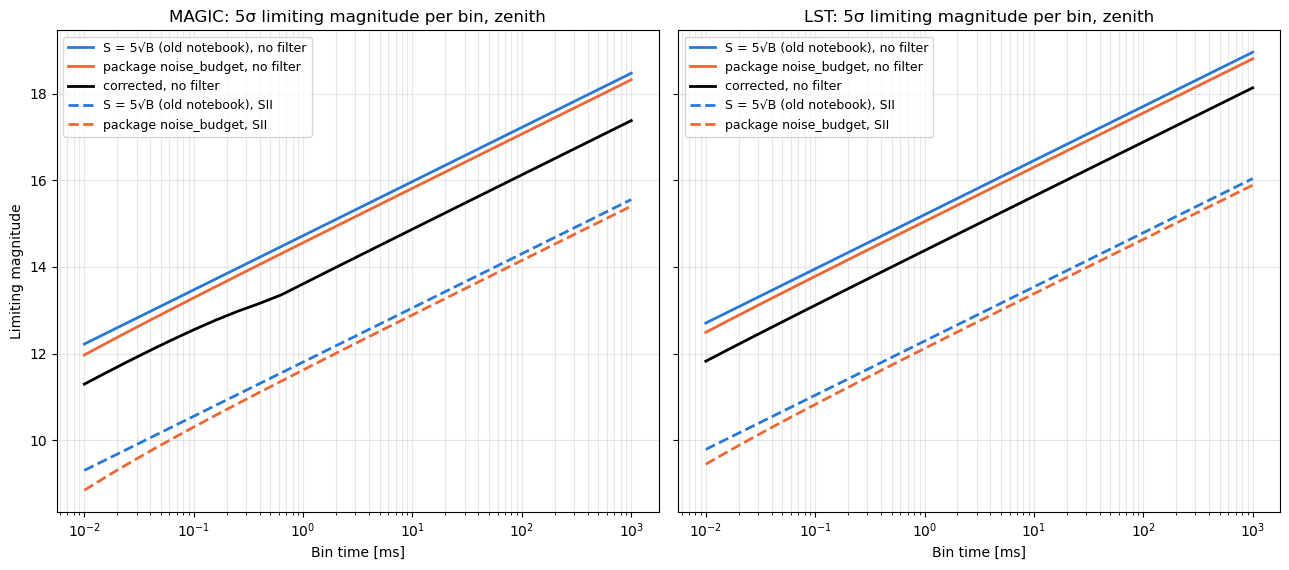

In [25]:
MAG_FINE = np.linspace(0, 22, 441)
LIM_BINS = np.logspace(-2, 3, 26)

def limiting_mag(snr_of_mag):
    snr = snr_of_mag(MAG_FINE)
    above = np.where(snr >= 5)[0]
    if len(above) == 0:
        return np.nan
    j = above[-1]
    if j + 1 >= len(MAG_FINE):
        return MAG_FINE[-1]
    return np.interp(np.log(5), [np.log(snr[j + 1]), np.log(snr[j])], [MAG_FINE[j + 1], MAG_FINE[j]])

fig, axes = tel_axes(sharey=True)
for ax, t in zip(axes, TELS):
    for instr, ls, flt in [(INSTR[t], "-", "no filter"), (INSTR_SII[t], "--", "SII")]:
        tbs = LIM_BINS * u.ms
        S0 = lambda m, tb: instr.num_photons_from_mag(tb.to_value(u.ms), m)
        old = [limiting_mag(lambda m: S0(m, tb) / np.sqrt(instr.number_nsb_photons() * tb.to_value(u.ns))) for tb in tbs]
        pkg = [limiting_mag(lambda m: 1 / package_budget(instr, m, tb)["sigma_total"]) for tb in tbs]
        cor = [limiting_mag(lambda m: 1 / corrected_budget(instr, m, tb)["sigma_total"]) for tb in tbs] \
            if instr.filter_type is None else None
        ax.plot(LIM_BINS, old, color=STEP_COLORS[0], ls=ls, lw=2, label=f"S = 5√B (old notebook), {flt}")
        ax.plot(LIM_BINS, pkg, color=STEP_COLORS[1], ls=ls, lw=2, label=f"package noise_budget, {flt}")
        if cor is not None:
            ax.plot(LIM_BINS, cor, color="k", ls=ls, lw=2, label=f"corrected, {flt}")
    ax.set(xscale="log", xlabel="Bin time [ms]", title=f"{t}: 5σ limiting magnitude per bin, zenith")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
axes[0].set_ylabel("Limiting magnitude")
plt.tight_layout()
plt.savefig(f"./Limiting_magnitude.png", dpi=200)
plt.show()

## 13 - Theory against the measured SNR
`snr_report` (what `kbo-night snr` writes) gives the measured `detr` SNR and the package theory at the observation's
airmass and mirror throughput (`theo_obs_B`). Added here, notebook only:

- `theo_corr_B`: corrected budget (CALSPEC + colour + PSF containment + hexagonal NSB + scintillation + scaled floor);
- `theo_corr_measnsb_B`: the same with B taken from the measured NSB/star ratio of section 9 (pedestal included, so
  pessimistic).

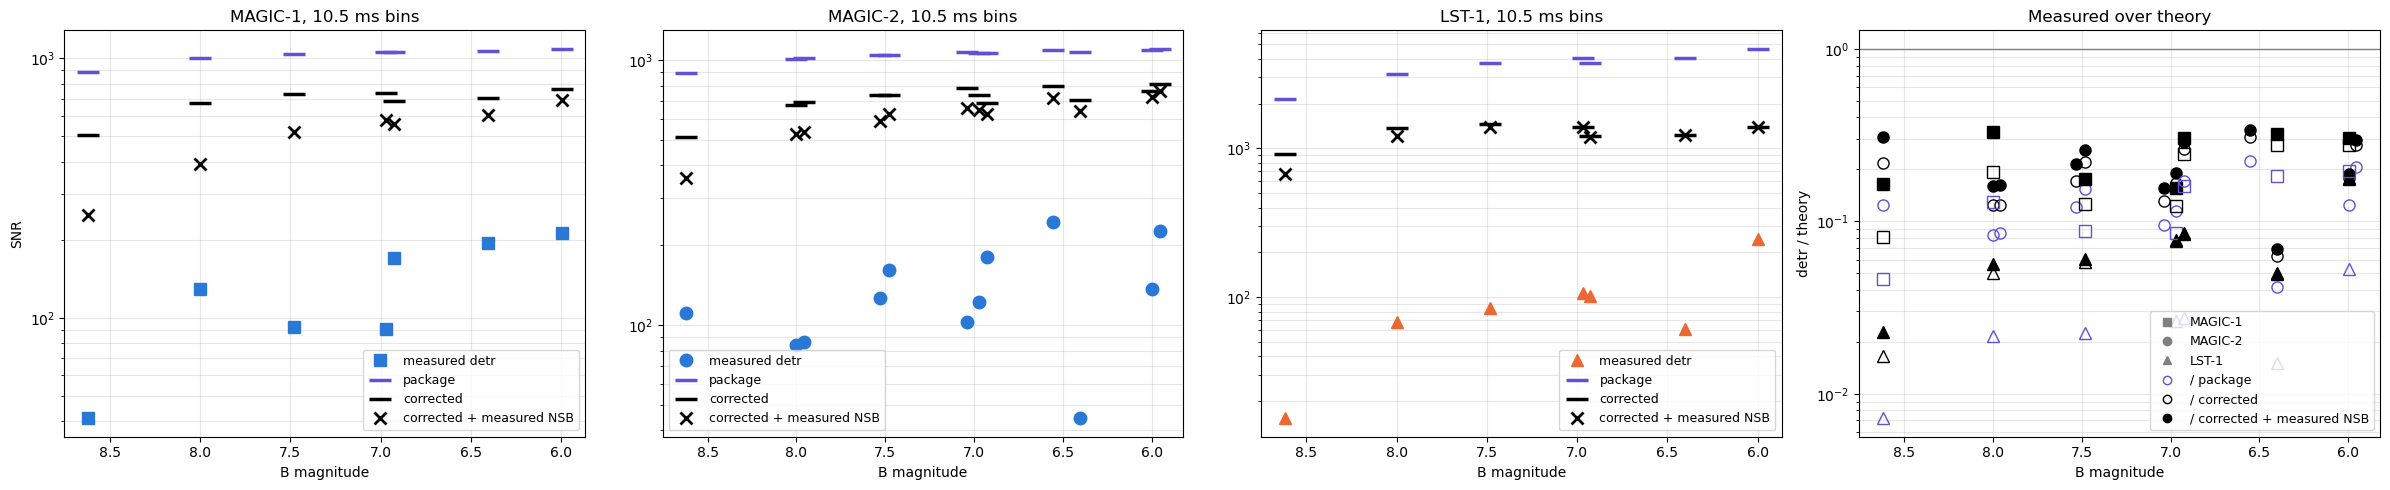

detr / package  detr / corrected  detr / corrected + measured NSB
n_bin telescope                                                                   
10    LST-1               0.028             0.055                            0.059
      MAGIC-1             0.156             0.217                            0.344
      MAGIC-2             0.160             0.214                            0.256
20    LST-1               0.023             0.058                            0.061
      MAGIC-1             0.129             0.192                            0.303
      MAGIC-2             0.122             0.175                            0.202
200   LST-1               0.011             0.091                            0.091
      MAGIC-1             0.062             0.161                            0.206
      MAGIC-2             0.042             0.119                            0.126

In [26]:
res = snr_report(log, lcs=lcs)
extra = []
for (night_name, obs_name, tel_name, n_bin), r in res.iterrows():
    obs = log.nights[night_name].observations[obs_name]
    i = INSTR[KIND[tel_name]]
    kw = dict(airmass=r["airmass"], throughput=r["mirror_throughput"], psf=psf_containment(night_name, tel_name),
              teff=teff_from_spectral_type(obs.spectral_type))
    tb = r["bin_ms"] * u.ms
    extra.append({"night": night_name, "observation": obs_name, "telescope": tel_name, "n_bin": n_bin,
                  "psf_containment": kw["psf"],
                  f"theo_corr_{BAND}": 1 / corrected_budget(i, obs.magnitude(BAND), tb, **kw)["sigma_total"],
                  f"theo_corr_measnsb_{BAND}": 1 / corrected_budget(
                      i, obs.magnitude(BAND), tb, nsb_over_star=bs.loc[(night_name, obs_name, tel_name), "measured"], **kw)["sigma_total"]})
res = res.join(pd.DataFrame(extra).set_index(["night", "observation", "telescope", "n_bin"]))
THEO = {f"theo_obs_{BAND}": "package", f"theo_corr_{BAND}": "corrected", f"theo_corr_measnsb_{BAND}": "corrected + measured NSB"}
for col in THEO:
    res[f"detr / {THEO[col]}"] = res["detr"] / res[col]

THEO_STYLE = {f"theo_obs_{BAND}": dict(color="#6250d6", marker="_", ms=16, mew=2.5),
              f"theo_corr_{BAND}": dict(color="k", marker="_", ms=16, mew=2.5),
              f"theo_corr_measnsb_{BAND}": dict(color="k", marker="x", ms=9, mew=2)}
sub = res.xs(N_BINS[1], level="n_bin")
tel_names = list(MARK)
fig, axes = plt.subplots(1, len(tel_names) + 1, figsize=(6 * (len(tel_names) + 1), 5), sharey=False)
for ax, tel_name in zip(axes, tel_names):
    rows_t = sub.xs(tel_name, level="telescope")
    mags_t = [log.nights[n].observations[o].magnitude(BAND) for n, o in rows_t.index]
    ax.plot(mags_t, rows_t["detr"], MARK[tel_name], ms=9, color=TEL_COLORS[KIND[tel_name]], ls="", label="measured detr")
    for col, style in THEO_STYLE.items():
        ax.plot(mags_t, rows_t[col], ls="", label=THEO[col], **style)
    ax.set(yscale="log", xlabel=f"{BAND} magnitude", title=f"{tel_name}, {sub['bin_ms'].iloc[0]:.1f} ms bins")
    ax.invert_xaxis(); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
axes[0].set_ylabel("SNR")
ax = axes[-1]
for (night_name, obs_name, tel_name), r in sub.iterrows():
    m = log.nights[night_name].observations[obs_name].magnitude(BAND)
    for col, style in THEO_STYLE.items():
        ax.plot(m, r[f"detr / {THEO[col]}"], MARK[tel_name], ms=8, color=style["color"],
                mfc=style["color"] if col == f"theo_corr_measnsb_{BAND}" else "none")
handles = [plt.Line2D([], [], color="grey", marker=mk, ls="", label=t) for t, mk in MARK.items()]
handles += [plt.Line2D([], [], color="#6250d6", marker="o", mfc="none", ls="", label="/ package"),
            plt.Line2D([], [], color="k", marker="o", mfc="none", ls="", label="/ corrected"),
            plt.Line2D([], [], color="k", marker="o", ls="", label="/ corrected + measured NSB")]
ax.axhline(1, color="grey", lw=1)
ax.set(yscale="log", xlabel=f"{BAND} magnitude", ylabel="detr / theory", title="Measured over theory")
ax.invert_xaxis(); ax.grid(alpha=0.3, which="both"); ax.legend(handles=handles, fontsize=9)
plt.tight_layout()
plt.savefig(f"./SNR_measured_and_theory.png", dpi=200)
plt.show()

ratio_cols = [f"detr / {v}" for v in THEO.values()]
res.groupby(["n_bin", "telescope"])[ratio_cols].median()

## 14 - Findings
Numbers below are recomputed by the cell; the verdicts are in the text after it.

In [23]:
i_m, i_l = INSTR["MAGIC"], INSTR["LST"]
findings = pd.DataFrame([
    ("Vega zero point (no filter)", "flat 2020.2 ph/cm2/s/A", f"CALSPEC: star photons / {vega_ratio['MAGIC']:.2f}"),
    ("star colour", "Vega colours", f"B5-B9.5: x {colour_correction(i_m, 15000):.3f} - {colour_correction(i_m, 10000):.3f}"),
    ("scintillation, 10 ms", f"{package_budget(i_m, REF_MAG, REF_BIN)['sigma_scint']:.1e} (MAGIC)",
     f"{scint_corrected(aperture_m(i_m), 0.01, 1, i_m.site_altitude_m):.1e} (joined), long-exposure alone "
     f"{scint_long(aperture_m(i_m), 0.01, 1, i_m.site_altitude_m):.1e}"),
    ("PSF in pixel", "100 %", ", ".join(f"{k[1]} {k[0]}: {v:.0%}" for k, v in PSF_CONTAINMENT.items())),
    ("pixel shape", "circle", f"hexagon: NSB x {HEX_OVER_CIRCLE:.3f}"),
    ("MAGIC efficiency @400 nm", f"{params.loc['total telescope efficiency @400 nm', 'MAGIC (package)']:.3f}",
     f"MAGIC-LST.yml {params.loc['total telescope efficiency @400 nm', 'MAGIC (MAGIC-LST.yml)']:.3f}"),
    ("NSB / star (median measured / package)", "", "; ".join(f"{t}: {v:.1f}" for t, v in
                                                       bs.groupby('telescope')['measured / package'].median().items())),
    ("variance floor k", "MAGIC 2, LST 0", f"radiometer 250/110 = {250e6 / float(II['b_v'][0]):.2f}; x ((S+B)/S)^2"),
], columns=["item", "package", "notebook"]).set_index("item")
findings

,package,notebook
item,,
Vega zero point (no filter),flat 2020.2 ph/cm2/s/A,CALSPEC: star photons / 1.82
star colour,Vega colours,B5-B9.5: x 1.058 - 1.005
"scintillation, 10 ms",1.8e-04 (MAGIC),"7.2e-04 (joined), long-exposure alone 5.3e-03"
PSF in pixel,100 %,"MAGIC-2 2025-12-16: 99%, MAGIC-1 2026-03-08: 1..."
pixel shape,circle,hexagon: NSB x 1.103
MAGIC efficiency @400 nm,0.178,MAGIC-LST.yml 0.096
NSB / star (median measured / package),,LST-1: 8.9; MAGIC-1: 11.7; MAGIC-2: 7.0
variance floor k,"MAGIC 2, LST 0",radiometer 250/110 = 2.27; x ((S+B)/S)^2


### Verdicts

**Wrong in the package**
1. **Vega zero point without a filter.** `number_of_photons_from_Vega['QE'] = 2020.2` ph cm⁻² s⁻¹ Å⁻¹ is above the
   CALSPEC spectrum at every wavelength. Folded with the MAGIC or LST response it should be 1113, so every unfiltered
   star count is **1.82× too high** (shot-noise SNR 1.35× too high). The old notebook's independent blackbody + Roach
   method agrees with CALSPEC to ~10 %, so 2020.2 is the outlier. Fix: compute the zero point from
   `alpha_lyr_stis_011.fits` × response inside `num_photons_from_mag`.
2. **Scintillation units.** The package uses Osborn's SI coefficient with D in **cm** (σ ÷ 21.5) and 1/(2t) instead of
   1/t (σ ÷ √2), so σ is ~30× too small. Its t^(−1/2) law is also only valid for t ≫ D/v (~0.5 s for these dishes).
   Below that, scintillation saturates at ~7·10⁻⁴ (MAGIC) and ~6·10⁻⁴ (LST) for v = 20 m/s and C_Y = 1.5. The package
   value happens to cross the saturated one near 1 ms. Either way scintillation is far below the ~1 % noise measured
   in the SNR study, so it does not explain the gap.
3. Dead code: `star_flux_folded_with_transmission` calls an unbound `star_flux` (NameError), and the
   `nsb_per_telescope` dictionary is unused and disagrees with the computed rates.

**Missing from the package**
4. **PSF containment.** If the MAGIC "PSF 39 %" value is a diameter (σ = PSF/2), 98–99.7 % of the light falls in the
   pixel and the PSF is irrelevant. If it is σ, only 62–77 % does. LST-1 (D80 = 46.7 mm): 87 %. Both assume a centred
   star; any mispointing lowers them.
5. **Hexagonal pixels**: NSB × 1.103.
6. **Variance floor scaling.** The floor is the radiometer equation (k = 250 MHz / 110 MHz = 2.27, next to the fitted
   k ≈ 2), so it is relative to the whole variance: × ((S+B)/S)². By the same argument it should apply to LST-1 too.
   With k = 2.27, LST-1's corrected SNR at 10 ms halves (B = 7: 1667 → 826), which would bring its detr/theory ratio to
   MAGIC's level. This contradicts the SNR study's "LST-1 shows no floor" and is left open.
7. **Measured NSB.** The theory never uses it. Measured NSB/star is **7–12× the package prediction** (4–6× after the
   corrections). Either the dark-run level is dominated by the electronic pedestal, or several times less star light
   reaches the pixel than modelled. A run with the camera closed (pedestal only) would separate the two.

**Placeholders or unclear**
8. MAGIC optics are LST curves × scalars. Its 400 nm efficiency (0.178) is 1.9× the MAGIC-LST.yml value (0.096). The
   difference is the yml's "halo 70 % × PSF 70 %". The PSF part looks pessimistic for the logged PSFs, but the halo
   (light scattered out of the PSF core) is in neither model.
9. MODTRAN extinction is k(440 nm) = 0.30 and k(550 nm) = 0.18 mag/airmass, against the log's k_B = 0.23 and
   k_V = 0.13. The model atmosphere is dustier than a typical ORM night (star light ~6 % low at the zenith): small, and
   in the opposite direction to the gap.
10. F = 1.15: MAGIC-LST.yml calls it "F⁻¹". Whether it is F or F² changes the shot term by ≤ 15 %. Electronic noise
    (0.7 p.e. per bin) is negligible at every bin size, but it is modelled as a per-bin readout, which does not fit a
    variance signal.

**Net effect.** At ~10 ms the median measured/theory ratio goes from 0.12–0.13 to 0.18–0.19 for MAGIC and from 0.023
to 0.058 for LST-1. The corrections explain a factor 1.5–2.5. The remaining factor 5–6 for MAGIC (3–5 with the measured NSB) and ~17 for
LST-1 is not
per-sample white noise. It matches the correlated 0.1–1 Hz noise found in the SNR study (`red_noise_rms = 0` in every
curve here) and, for LST-1, possibly a missing variance floor.